# Diamond clustering

**Research question.** What groups of diamonds emerge from their weight, dimensions, proportions, color and clarity? How consistently do K-Means and DBSCAN recover those groups across the original and reduced feature spaces, and how do the groups differ in price?

**Working hypothesis.** Carat and physical dimensions will account for many of the differences between groups. Color, clarity and proportions may distinguish diamonds of similar size. Groups of heavier diamonds are expected to have higher median prices.

The data come from `diamonds_unsupervised.csv`. `diamond_id` identifies records. Color is ordered from 1 to 7 (J, I, H, G, F, E, D). Clarity is ordered from 1 to 8 (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF). Price is used in descriptive plots and cluster profiles. Each fitted representation and clustering algorithm uses the same eight physical and grade features.

In [90]:
import numpy as np
import pandas as pd

#Plotting
import matplotlib.pyplot as plt
import seaborn as sns

#Clustering algos
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score, silhouette_score

#Dim reductions algos
from sklearn.decomposition import NMF, PCA
from sklearn.manifold import TSNE

#Scaling algos
from sklearn.preprocessing import MinMaxScaler, StandardScaler


from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 145})

df_init = pd.read_csv("diamonds_unsupervised.csv")
raw_row_count = len(df_init)

## 1. Exploratory data analysis

### Initial data checks

In [91]:
# First look at the data
df_init.head()

,diamond_id,carat,depth_pct,table_pct,price_usd,length_mm,width_mm,height_mm,color_grade,clarity_grade
0,D7-00001,1.51,58.1,67.0,10553,7.59,7.49,4.38,4,4
1,D7-00002,0.33,63.1,55.0,567,4.38,4.40,2.77,7,3
2,D7-00003,1.01,62.7,58.0,4909,6.38,6.34,3.99,7,3
3,D7-00004,0.71,60.6,56.0,3674,5.78,5.81,3.51,7,3
4,D7-00005,0.31,62.0,54.0,698,4.39,4.35,2.71,3,5


In [92]:
# Data shape
print(f"Data shape: {df_init.shape}")

Data shape: (5023, 10)


In [93]:
# Exclude the record identifier from numeric summaries.
display(df_init.drop(columns="diamond_id").describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
carat,5023.0,0.87,0.50,0.21,0.46,0.80,1.06,5.01
depth_pct,4993.0,62.22,2.28,50.80,61.00,62.10,63.50,79.00
table_pct,4993.0,58.12,2.82,44.00,56.00,58.00,59.00,95.00
price_usd,5023.0,4148.85,3966.82,337.00,1108.00,2883.00,5440.50,18818.00
length_mm,5023.0,5.88,1.14,0.00,4.90,5.92,6.57,10.74
width_mm,5023.0,5.88,1.40,0.00,4.89,5.90,6.57,58.90
height_mm,5023.0,3.65,0.84,0.00,3.02,3.68,4.09,31.80
color_grade,5023.0,4.33,1.71,1.00,3.00,4.00,6.00,7.00
clarity_grade,5023.0,3.76,1.62,1.00,3.00,4.00,5.00,8.00


In [94]:
# Summarize missing values and repeated records.
missing = pd.DataFrame({
    "Missing rows": df_init.isna().sum(),
    "Missing (%)": df_init.isna().mean().mul(100).round(2),
})
display(missing)
print(f"Rows with any missing value: {df_init.isna().any(axis=1).sum():,}")
print(f"Exact duplicate rows: {df_init.duplicated().sum():,}")
print(f"Repeated diamond IDs: {df_init['diamond_id'].duplicated().sum():,}")

,Missing rows,Missing (%)
diamond_id,0,0.0
carat,0,0.0
depth_pct,30,0.6
table_pct,30,0.6
price_usd,0,0.0
length_mm,0,0.0
width_mm,0,0.0
height_mm,0,0.0
color_grade,0,0.0
clarity_grade,0,0.0


Rows with any missing value: 60
Exact duplicate rows: 0
Repeated diamond IDs: 0


In [95]:
# Identical recorded values under another ID could be repeat entries.
df_duplicates = df_init.drop(columns="diamond_id").duplicated()
duplicated_indexes = df_duplicates[df_duplicates]
print(f"Possible duplicate records: {df_duplicates.sum():,}")

Possible duplicate records: 6


In [96]:
dimension_cols = ["length_mm", "width_mm", "height_mm"]
proportion_cols = ["depth_pct", "table_pct"]

# Check basic ranges before removing zero-dimension rows.
non_physical_data = df_init[df_init[dimension_cols].eq(0).any(axis=1)]
checks = pd.Series({
    "Rows with a zero dimension": len(non_physical_data),
    "Rows with a negative dimension": df_init[dimension_cols].lt(0).any(axis=1).sum(),
    "Rows with nonpositive carat": df_init["carat"].le(0).sum(),
    "Rows with depth % outside (0, 100]": (
        df_init["depth_pct"].le(0) | df_init["depth_pct"].gt(100)
    ).sum(),
    "Rows with table % outside (0, 100]": (
        df_init["table_pct"].le(0) | df_init["table_pct"].gt(100)
    ).sum(),
    "Rows with nonpositive price": df_init["price_usd"].le(0).sum(),
    "Color grades outside the scale": (
        df_init["color_grade"].notna() & ~df_init["color_grade"].isin(range(1, 8))
    ).sum(),
    "Clarity grades outside the scale": (
        df_init["clarity_grade"].notna() & ~df_init["clarity_grade"].isin(range(1, 9))
    ).sum(),
}, name="Rows flagged")
display(checks.to_frame())
print(f"Possible repeats also flagged for zero dimensions: "
      f"{len(non_physical_data.index.intersection(duplicated_indexes.index)):,}")

,Rows flagged
Rows with a zero dimension,20
Rows with a negative dimension,0
Rows with nonpositive carat,0
"Rows with depth % outside (0, 100]",0
"Rows with table % outside (0, 100]",0
Rows with nonpositive price,0
Color grades outside the scale,0
Clarity grades outside the scale,0


Possible repeats also flagged for zero dimensions: 1


Thirty rows lack a depth percentage and another 30 lack a table percentage. EDA uses available observations, and the modeling step reports its complete-case exclusion. The data contain six repeated combinations of recorded values under distinct IDs. Rounded measurements can coincide, so these are treated as possible repeats. Twenty rows have a zero physical dimension.

In [97]:
# Exclude zero dimensions first, then drop later matching entries.
print(f"Raw records: {len(df_init):,}")
df_init = df_init.drop(index=non_physical_data.index)
print(f"After excluding zero dimensions: {len(df_init):,}")
df_init = df_init.drop(index=duplicated_indexes.index, errors="ignore")
print(f"Rows available for EDA: {len(df_init):,}")

Raw records: 5,023
After excluding zero dimensions: 5,003
Rows available for EDA: 4,998


### Distributions and relationships

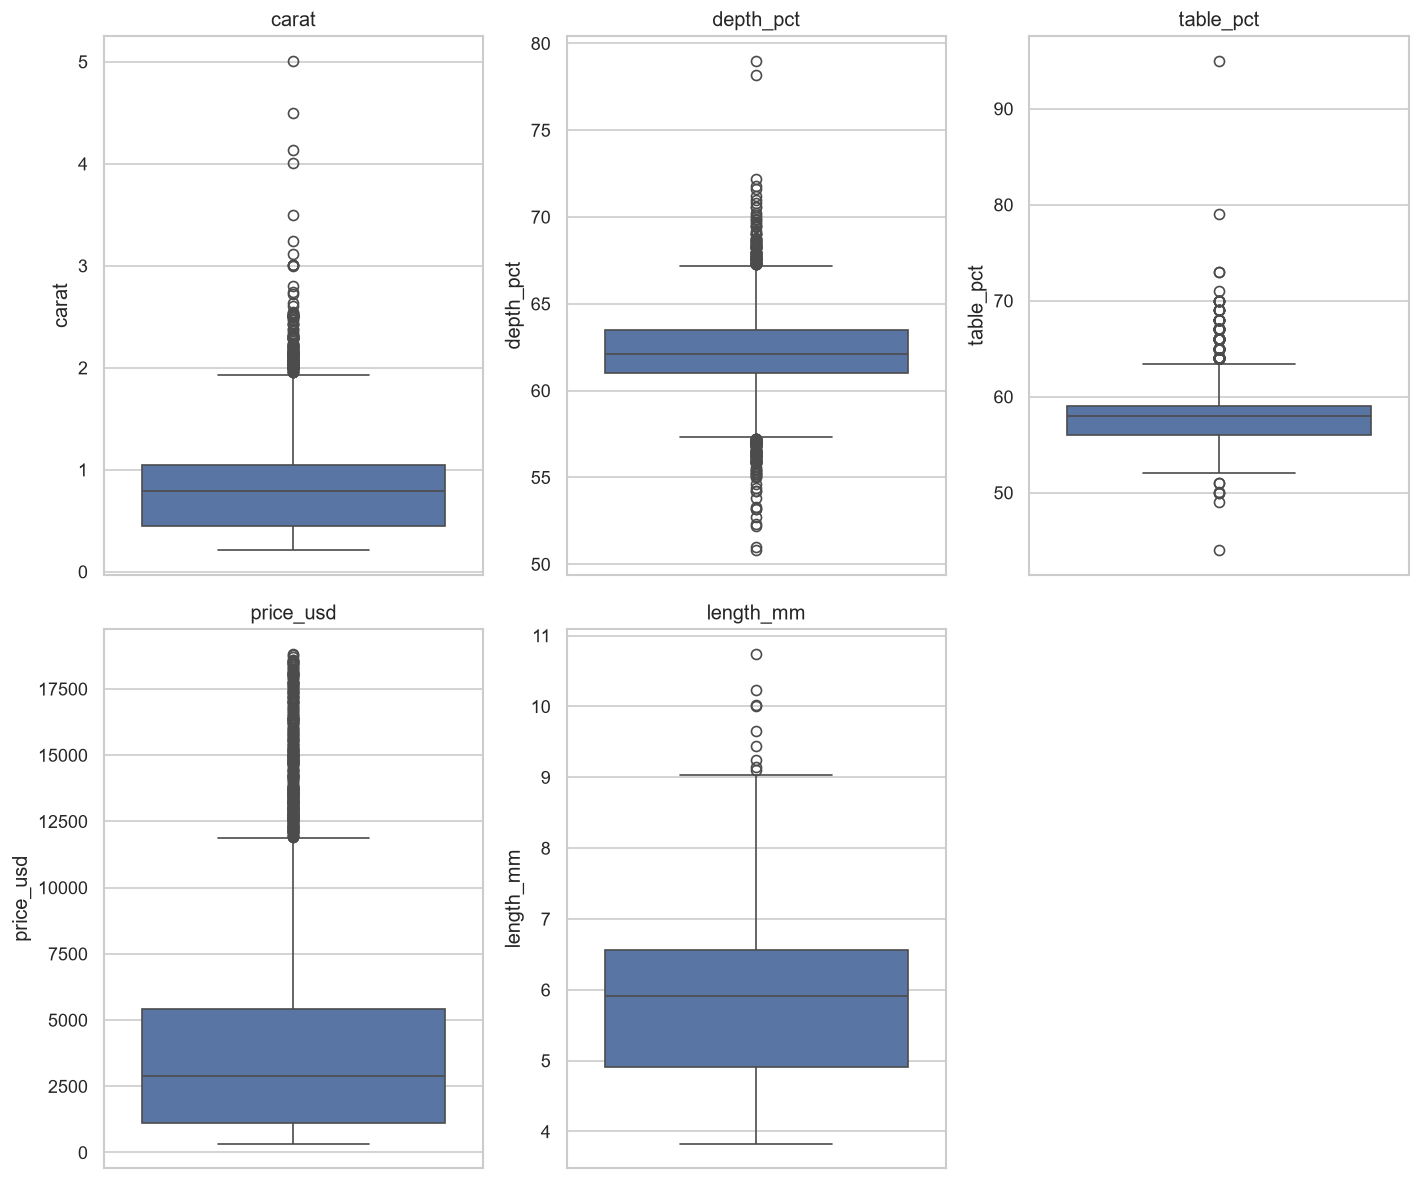

In [98]:
# Vertical boxplot for each numerical column
# Exclude categorical columns
cols = df_init.select_dtypes(include='number').columns.drop(
    ['color_grade', 'clarity_grade', 'height_mm', 'width_mm'], errors='ignore')

zoom_cols = ['width_mm', 'height_mm']
n_cols = (len(cols) + 1) // 2

fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 10))
axes = axes.flatten()

for col, ax in zip(cols, axes):
    sns.boxplot(data=df_init, y=col, ax=ax)
    ax.set_title(col)

    if col in zoom_cols:
        lower, upper = df_init[col].quantile([0.01, 0.99])
        ax.set_ylim(lower, upper)
        ax.set_title(f'{col} (Zoomed)')

for ax in axes[len(cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

**Graph explanation.** The carat and price panels have long upper tails. Depth and table percentages have narrow central bands with extremes on both sides. Length has a broader central spread in millimeters and several high values. Each box marks the middle half of its panel's observations.

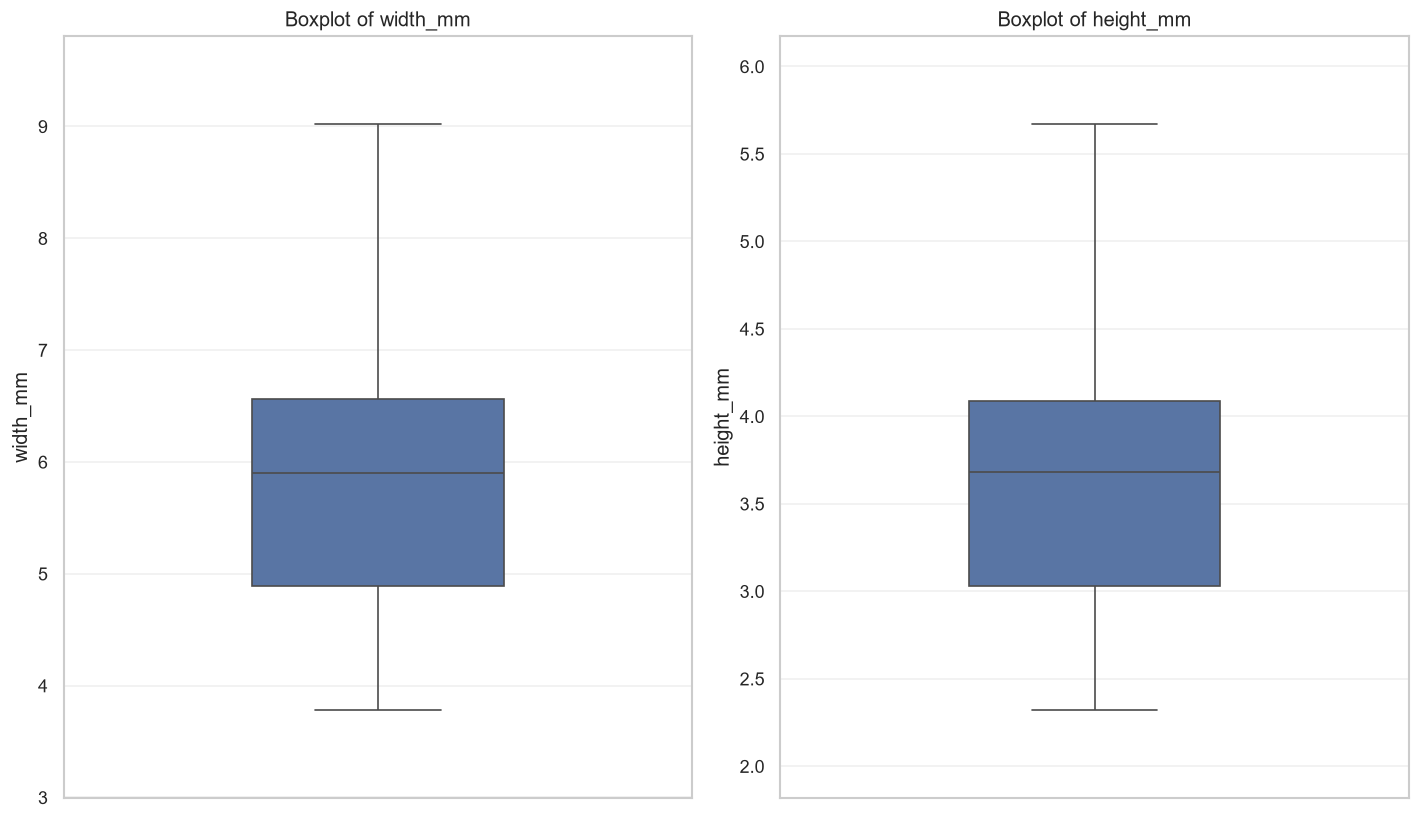

In [99]:
# Boxplots without displaying outliers

zoom_cols = ['width_mm', 'height_mm']

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

for col, ax in zip(zoom_cols, axes):
    sns.boxplot(
        data=df_init,
        y=col,
        ax=ax,
        showfliers=False,
        width=0.4
    )

    ax.set_title(f'Boxplot of {col}')
    ax.margins(y=0.15)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Graph explanation.** The width box shows the typical distance across the diamond. The height box shows the smaller spread from top to bottom. Both panels hide outlier markers to make these central ranges easier to compare.

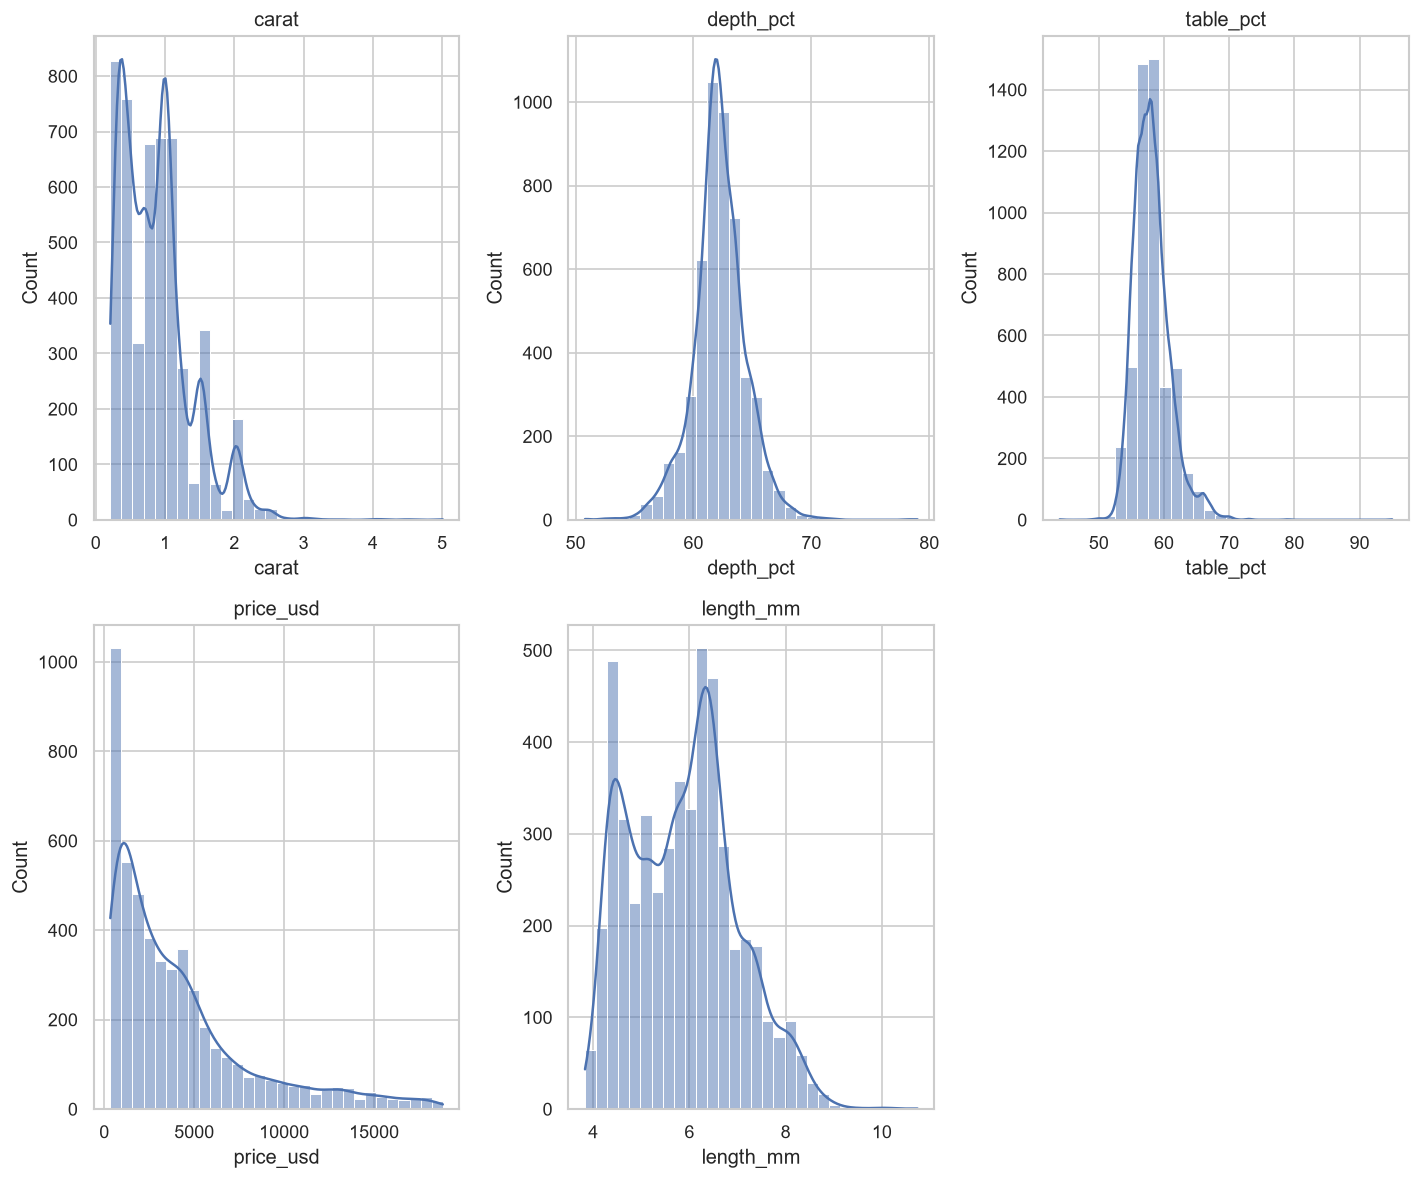

In [100]:
# Histograms with KDE curves arranged in 2 rows

fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 10))
axes = axes.flatten()

for col, ax in zip(cols, axes):
    data = df_init[col].dropna()

    if col in zoom_cols:
        lower, upper = data.quantile([0.01, 0.99])
        data = data[data.between(lower, upper)]

    sns.histplot(x=data, kde=True, bins=30, ax=ax)
    ax.set_title(f'{col} (Zoomed)' if col in zoom_cols else col)

for ax in axes[len(cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

**Graph explanation.** Carat is concentrated among smaller weights, and price is most frequent at the lower end. Depth and table percentage concentrate around 62% and 58%, respectively. Length shows several concentrations from about 4 to 7 mm. The smooth curves summarize the same distributions.

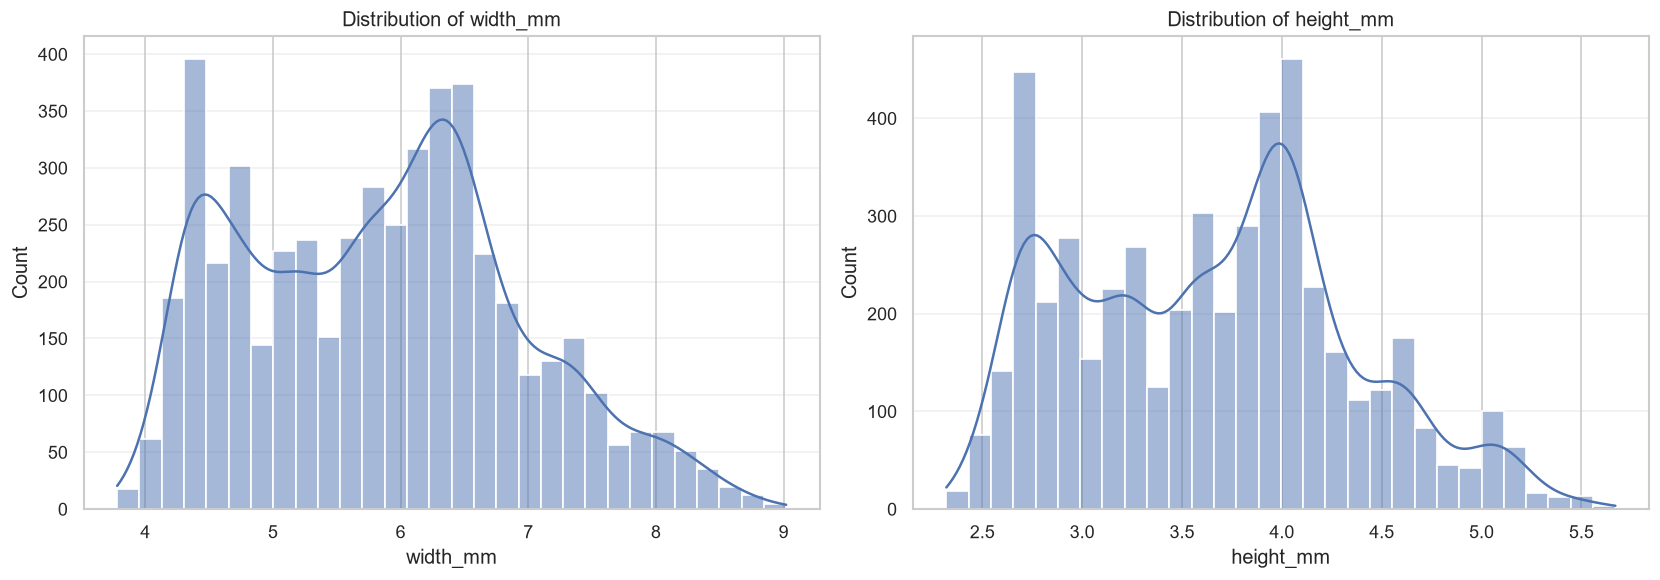

In [101]:
# Histograms with KDE, excluding IQR outliers from visualization

zoom_cols = ['width_mm', 'height_mm']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for col, ax in zip(zoom_cols, axes):
    Q1 = df_init[col].quantile(0.25)
    Q3 = df_init[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    data = df_init[col]
    data = data[data.between(lower, upper)]

    sns.histplot(x=data, kde=True, bins=30, ax=ax)

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.margins(x=0.05)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Graph explanation.** Width shows several peaks across the central range, and height is concentrated around roughly 3 to 4 mm. Each histogram shows values within 1.5 IQR of the quartiles for that measure.

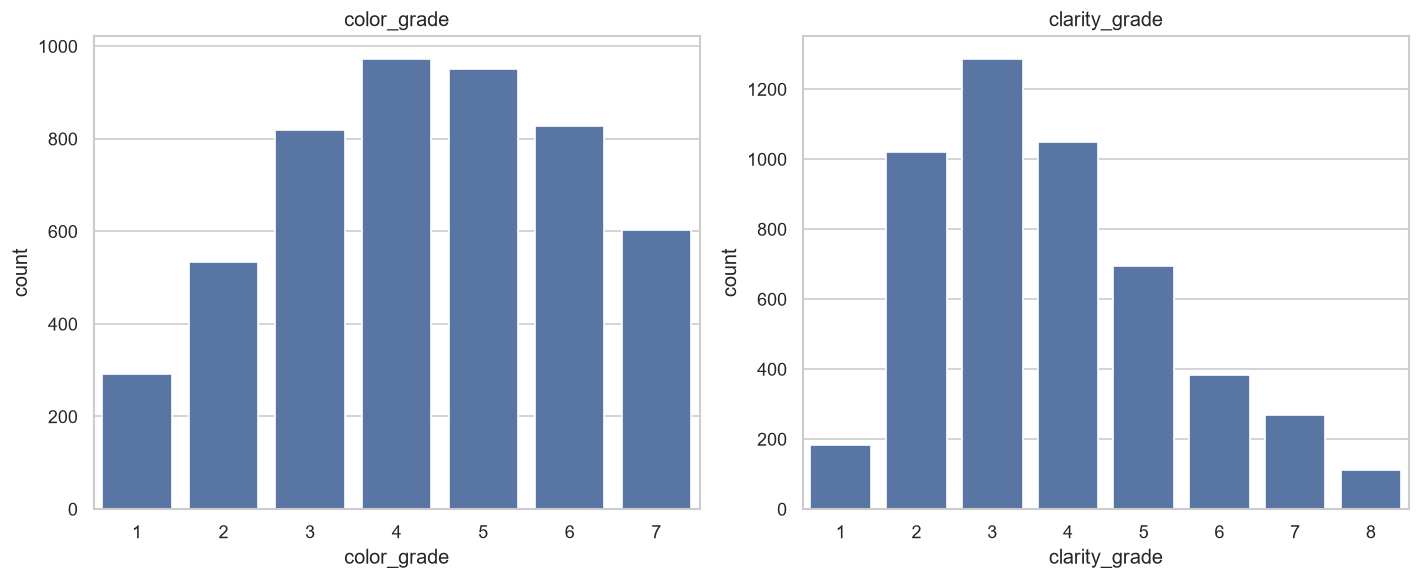

In [102]:
# Countplot for categorical columns

categorical_cols = ['color_grade', 'clarity_grade']



fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for col, ax in zip(categorical_cols, axes):
    sns.countplot(data=df_init, x=col, ax=ax,
                  order=sorted(df_init[col].dropna().unique()))
    ax.set_title(col)

plt.tight_layout()
plt.show()

**Graph explanation.** G (4) is the most common color grade and D (7) is the highest grade. SI1 (3) is the most common clarity grade and IF (8) is the highest grade. Grade numbers follow the ordering listed at the start.

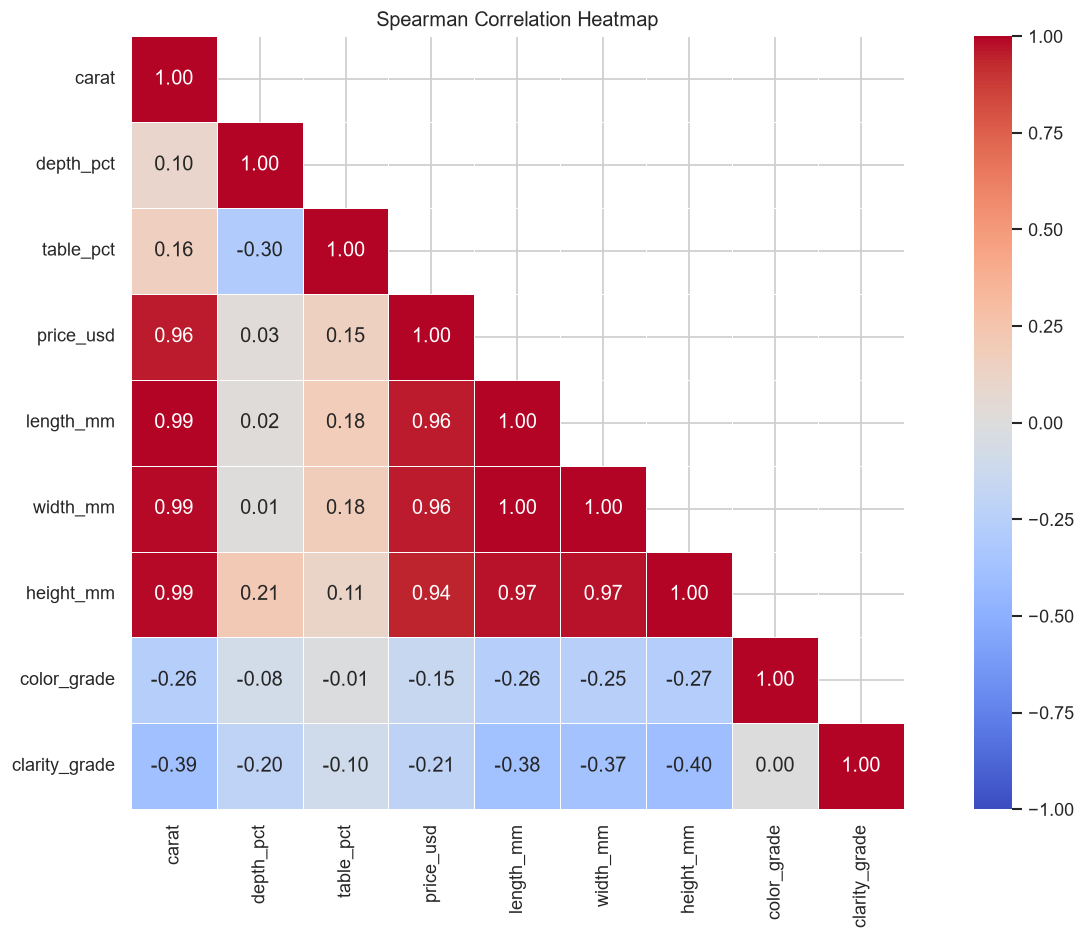

In [103]:
# Spearman correlation including ordinal categorical features

corr = df_init.corr(method='spearman', numeric_only=True)

# Mask the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()

**Graph explanation.** Spearman correlation measures monotonic association and accommodates the ordered grades. Carat, length, width and height move closely together. Price has a strong positive association with weight, and depth and table percentages are moderately negatively associated. The heatmap uses available pairs of measurements.

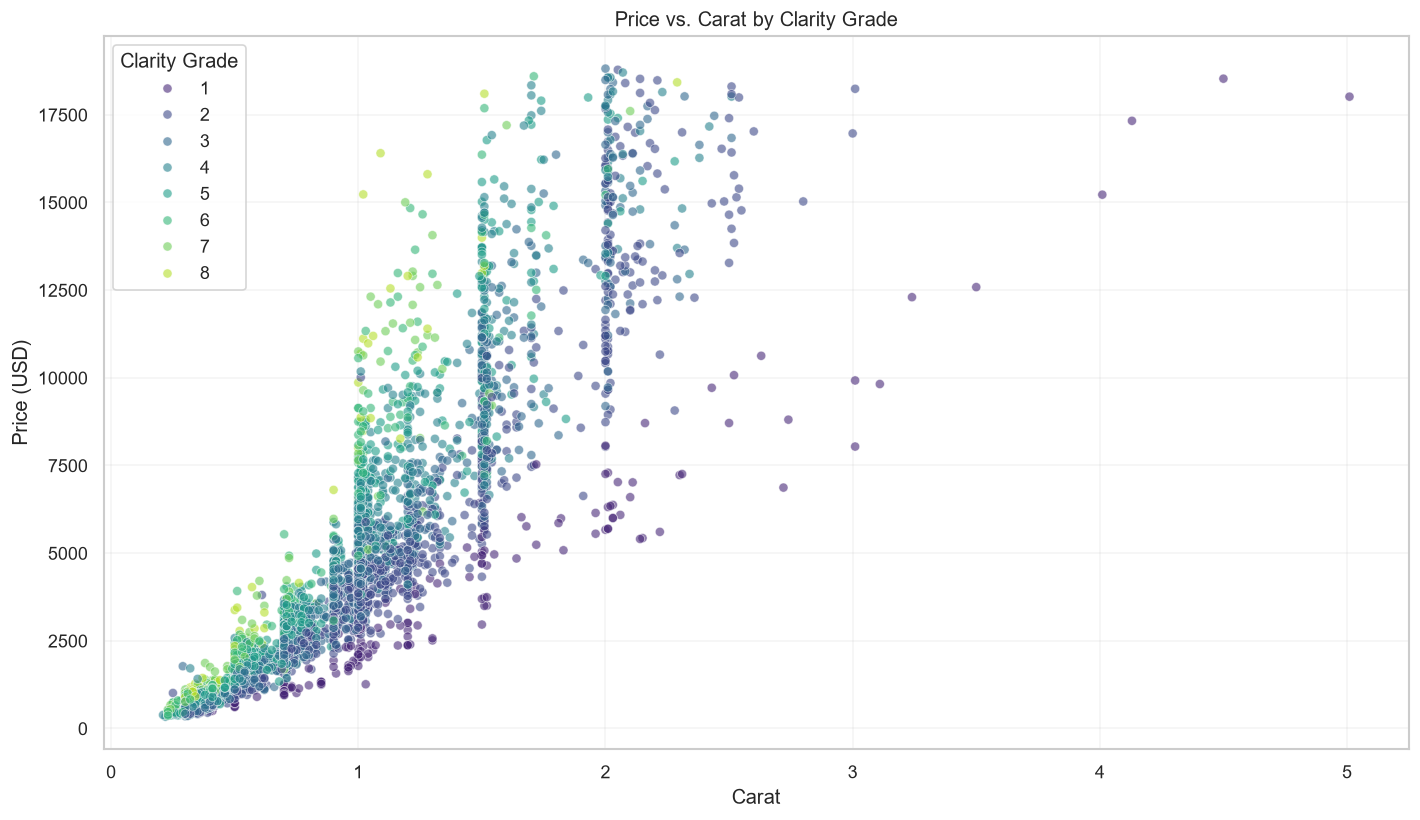

In [104]:
# Price vs. Carat by Clarity Grade

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_init,
    x='carat',
    y='price_usd',
    hue=df_init['clarity_grade'].astype('category'),
    palette='viridis',
    alpha=0.6,
    s=30
)

plt.title('Price vs. Carat by Clarity Grade')
plt.xlabel('Carat')
plt.ylabel('Price (USD)')
plt.legend(title='Clarity Grade')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** Price rises with carat, and the vertical spread shows substantial price differences at similar weights. The clarity colors show how several grades occur at the same weight.

width_mm: 181 rows excluded
height_mm: 233 rows excluded
length_mm: 184 rows excluded


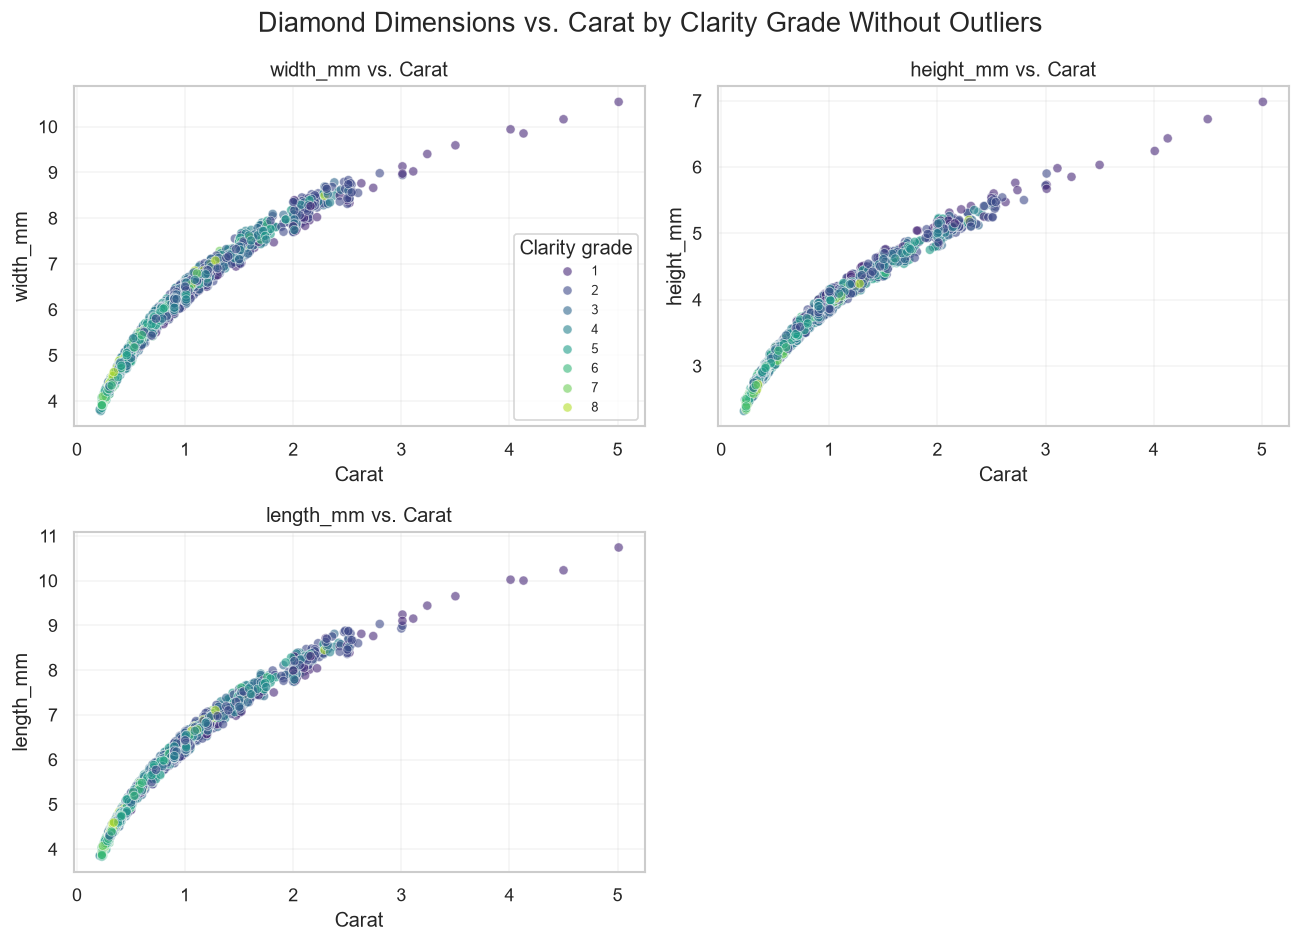

In [105]:
# Diamond dimensions vs. Carat by Clarity Grade without outliers

df_unique = df_init

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.ravel()
axes[-1].remove()

cols = ['width_mm', 'height_mm', 'length_mm']

for col, ax in zip(cols, axes):

    # Normalize dimension relative to diamond weight
    ratio = df_unique[col] / np.cbrt(df_unique['carat'].where(df_unique['carat'] > 0))

    # Calculate IQR boundaries
    Q1 = ratio.quantile(0.25)
    Q3 = ratio.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Exclude outliers
    df_filtered = df_unique[ratio.between(lower, upper)]

    sns.scatterplot(
        data=df_filtered,
        x='carat',
        y=col,
        hue=df_filtered['clarity_grade'].astype('category'),
        hue_order=sorted(df_unique['clarity_grade'].dropna().unique()),
        palette='viridis',
        alpha=0.6,
        s=30,
        ax=ax
    )

    ax.set_title(f'{col} vs. Carat')
    ax.set_xlabel('Carat')
    ax.set_ylabel(col)
    if col == 'width_mm':
        ax.legend(title='Clarity grade', fontsize=8)
    else:
        ax.get_legend().remove()
    ax.grid(alpha=0.2)

    print(f'{col}: {len(df_unique) - len(df_filtered)} rows excluded')

plt.suptitle('Diamond Dimensions vs. Carat by Clarity Grade Without Outliers',
             fontsize=16)

plt.tight_layout()
plt.show()

**Graph explanation.** The width and length panels both rise steadily with weight. Height follows a similar pattern, with a wider band of points at some weights. Each panel uses its own display filter on dimension divided by the cube root of carat.

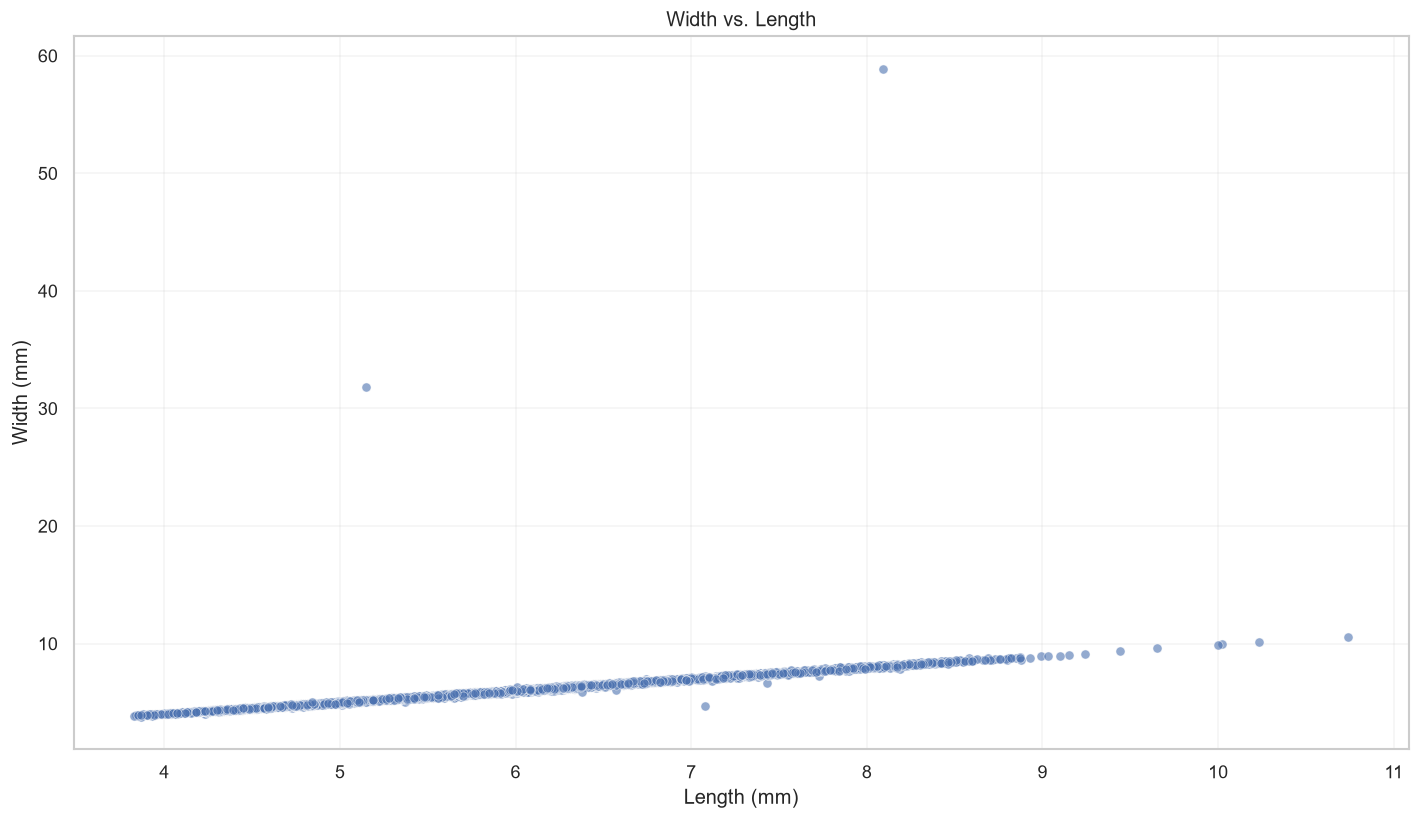

In [106]:
# Width vs. Length

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_init,
    x='length_mm',
    y='width_mm',
    alpha=0.6,
    s=30
)

plt.title('Width vs. Length')
plt.xlabel('Length (mm)')
plt.ylabel('Width (mm)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** Width extremes compress most observations near the bottom of this scale. In particular, the 31.8 mm and 58.9 mm widths are inconsistent with the other recorded dimensions and weights.

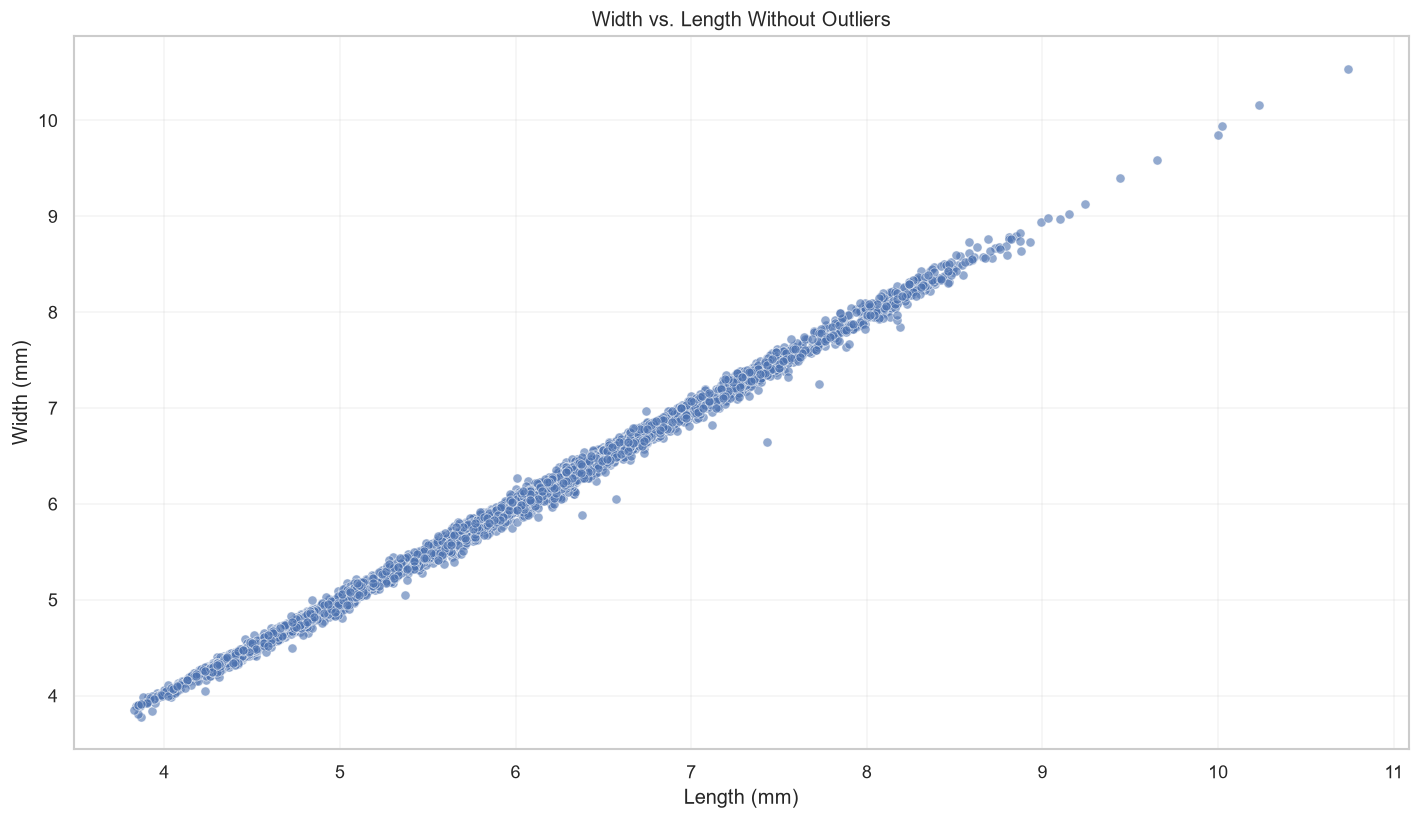

Outliers excluded: 3


In [107]:
# Width vs. Length without extreme outliers

df_filtered = df_init[
    (df_init['width_mm'] - df_init['length_mm']).abs() <= 1
]

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_filtered,
    x='length_mm',
    y='width_mm',
    alpha=0.6,
    s=30
)

plt.title('Width vs. Length Without Outliers')
plt.xlabel('Length (mm)')
plt.ylabel('Width (mm)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Outliers excluded: {len(df_init) - len(df_filtered)}")

**Graph explanation.** When the displayed width and length differ by at most 1 mm, a tight diagonal appears. This describes the plotted subset. The filtering is for this figure.

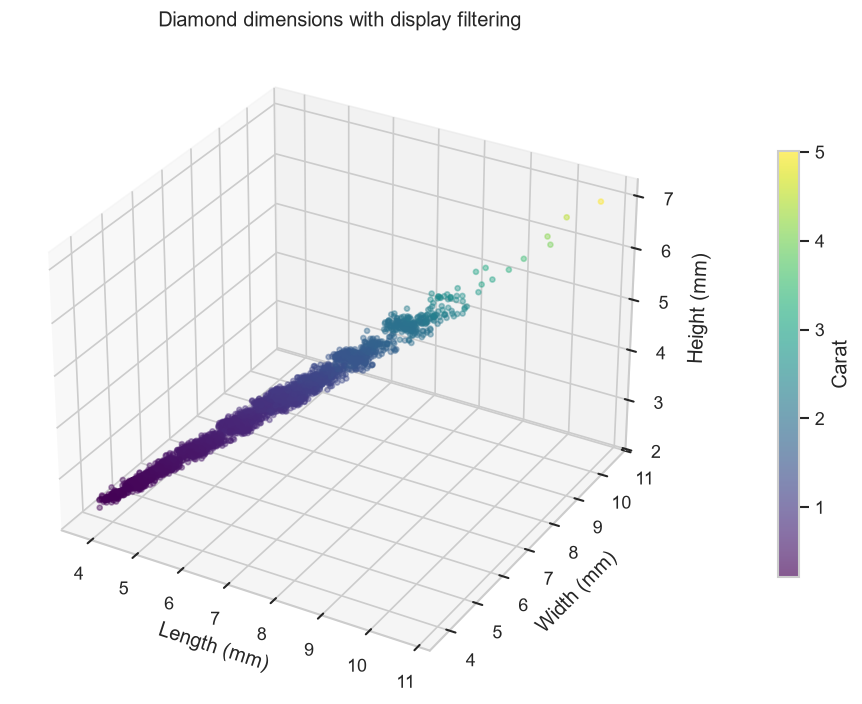

Rows excluded from the plot: 387


In [108]:
# 3D diamond dimensions without outliers

cols = ['length_mm', 'width_mm', 'height_mm']

mask = df_init['carat'] > 0

for col in cols:
    ratio = df_init[col] / np.cbrt(df_init['carat'])

    Q1 = ratio.quantile(0.25)
    Q3 = ratio.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = mask & ratio.between(lower, upper)

df_filtered_3d = df_init[mask]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
points = ax.scatter(
    df_filtered_3d["length_mm"], df_filtered_3d["width_mm"],
    df_filtered_3d["height_mm"], c=df_filtered_3d["carat"],
    cmap="viridis", s=9, alpha=0.65,
)
ax.set(xlabel="Length (mm)", ylabel="Width (mm)", zlabel="Height (mm)",
       title="Diamond dimensions with display filtering")
fig.colorbar(points, ax=ax, label="Carat", shrink=0.65, pad=0.12)
plt.tight_layout()
plt.show()
print(f"Rows excluded from the plot: {len(df_init) - len(df_filtered_3d):,}")

**Graph explanation.** Length, width and height rise together and larger values generally correspond to heavier diamonds. A carat-adjusted IQR filter selects the observations shown here.

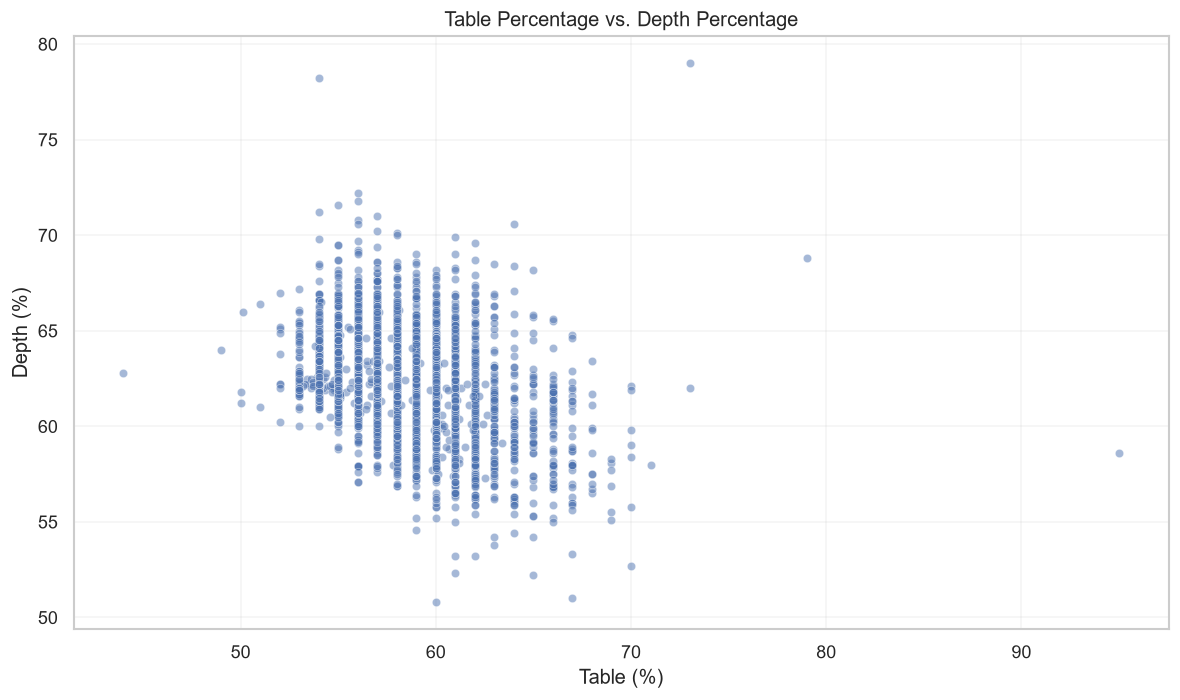

In [109]:
# Table Percentage vs. Depth Percentage

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_init,
    x='table_pct',
    y='depth_pct',
    alpha=0.5,
    s=25
)

plt.title('Table Percentage vs. Depth Percentage')
plt.xlabel('Table (%)')
plt.ylabel('Depth (%)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Graph explanation.** Larger table percentages tend to accompany lower depth percentages (Spearman correlation about -0.30). Most points sit in a compact region despite several extreme measurements.

color_grade,1,2,3,4,5,6,7
clarity_grade,,,,,,,
1,5322.5,2915.5,2966.0,2375.0,2098.0,2571.0,3819.5
2,4329.0,5407.0,4172.0,4047.0,3783.5,3632.0,3829.5
3,4161.0,4129.0,3753.0,3004.0,2700.0,2265.0,2690.0
4,3501.5,3258.0,4489.0,4022.0,2459.0,1814.0,1838.0
5,3062.0,2788.0,2401.0,2390.0,2381.0,1867.0,1752.0
6,7773.0,2448.0,1162.0,1838.0,2011.5,1013.5,1065.0
7,7670.5,863.0,800.5,1096.0,975.0,1011.0,1323.5
8,1221.0,673.0,1114.0,1056.0,1294.5,2040.5,3446.0


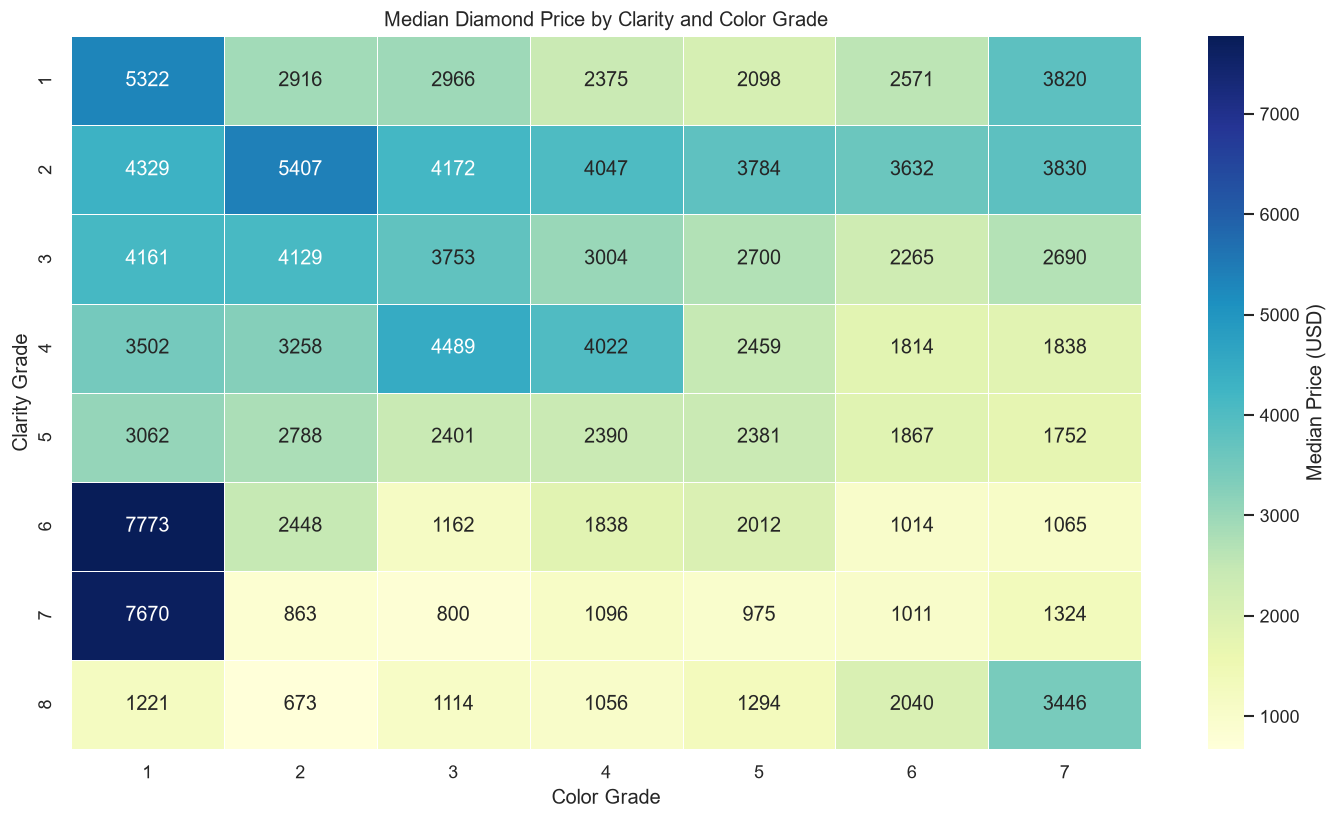

In [110]:
# Median price by clarity grade and color grade

median_price = df_init.groupby(
    ['clarity_grade', 'color_grade']
)['price_usd'].median().unstack()

# Display the matrix
display(median_price)

# Heatmap
plt.figure(figsize=(12, 7))

sns.heatmap(
    median_price,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Median Price (USD)'}
)

plt.title('Median Diamond Price by Clarity and Color Grade')
plt.xlabel('Color Grade')
plt.ylabel('Clarity Grade')
plt.tight_layout()
plt.show()

**Graph explanation.** Each cell shows the median price for that clarity and color combination. Raw medians depend on both group size and the mix of carat weights, so they describe this sample of diamonds.

### Additional EDA figures

These figures examine central ranges, grade differences and relationships between features.

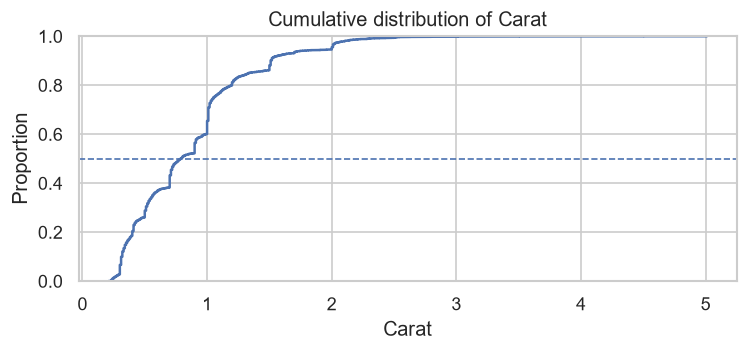

**Graph explanation.** Half the observed values are at or below 0.79. The middle half spans 0.45 to 1.05.

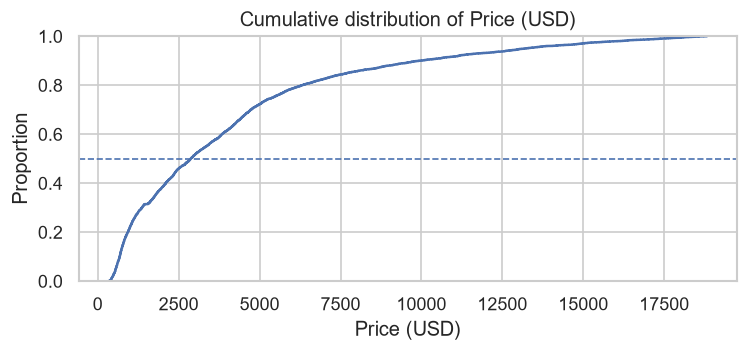

**Graph explanation.** Half the observed values are at or below 2,874.00. The middle half spans 1,103.50 to 5,410.75.

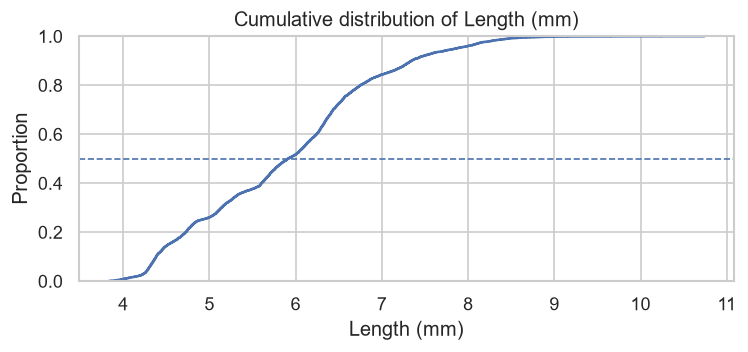

**Graph explanation.** Half the observed values are at or below 5.92. The middle half spans 4.91 to 6.57.

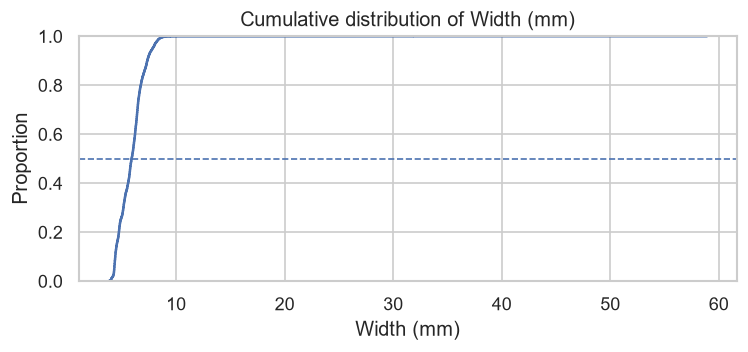

**Graph explanation.** Half the observed values are at or below 5.90. The middle half spans 4.89 to 6.56.

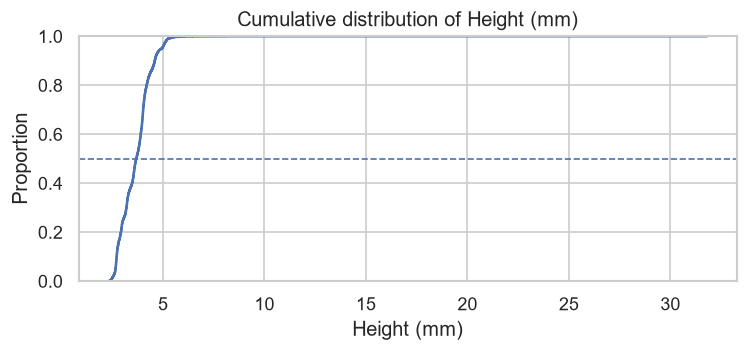

**Graph explanation.** Half the observed values are at or below 3.68. The middle half spans 3.03 to 4.09.

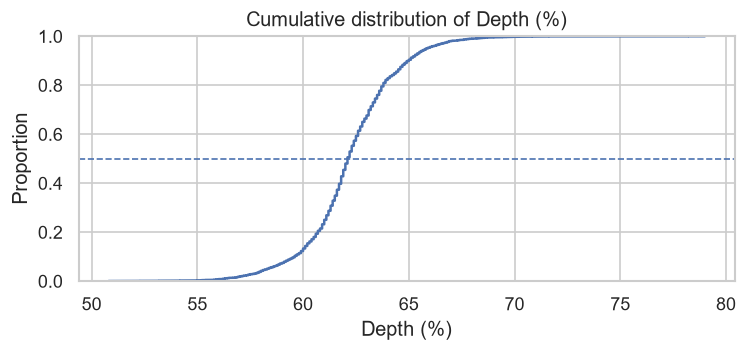

**Graph explanation.** Half the observed values are at or below 62.10. The middle half spans 61.00 to 63.50.

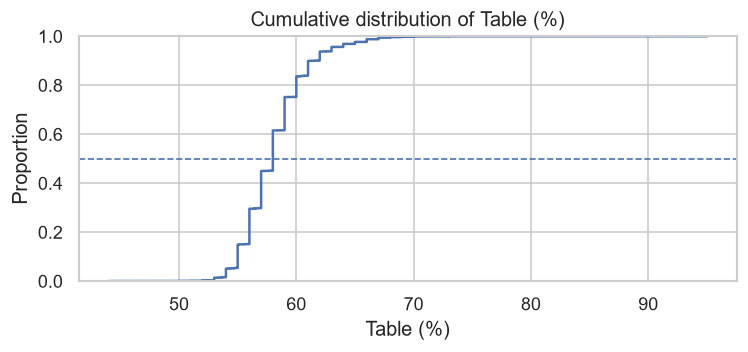

**Graph explanation.** Half the observed values are at or below 58.00. The middle half spans 56.00 to 59.00.

In [111]:
eda_names = {
    "carat": "Carat", "price_usd": "Price (USD)", "length_mm": "Length (mm)",
    "width_mm": "Width (mm)", "height_mm": "Height (mm)",
    "depth_pct": "Depth (%)", "table_pct": "Table (%)",
    "color_grade": "Color grade", "clarity_grade": "Clarity grade",
}
eda_numeric = list(eda_names)[:7]

# A separate figure and caption are shown for each comparison.
def eda_show(fig, caption):
    fig.tight_layout()
    plt.show()
    display(Markdown(f"**Graph explanation.** {caption}"))

for feature in eda_numeric:
    values = df_init[feature].dropna()
    q25, median, q75 = values.quantile([.25, .50, .75])
    fig, ax = plt.subplots(figsize=(6.4, 3.1))
    sns.ecdfplot(x=values, ax=ax)
    ax.axhline(.5, ls="--", lw=1)
    ax.set(xlabel=eda_names[feature], title=f"Cumulative distribution of {eda_names[feature]}")
    eda_show(fig, f"Half the observed values are at or below {median:,.2f}. "
             f"The middle half spans {q25:,.2f} to {q75:,.2f}.")

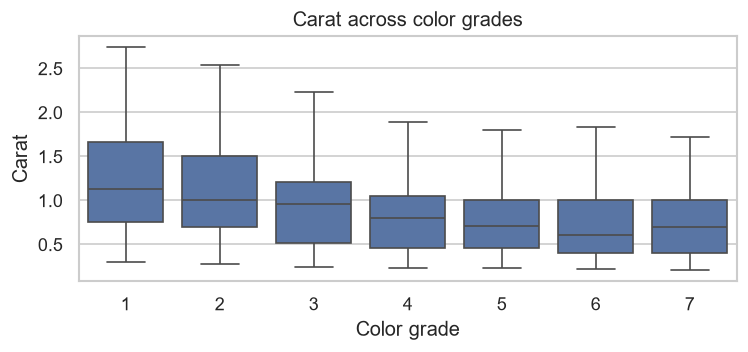

**Graph explanation.** Grade 6 has the lowest median (0.61). Grade 1 has the highest (1.13). The boxes and whiskers show the central range, with extreme markers hidden.

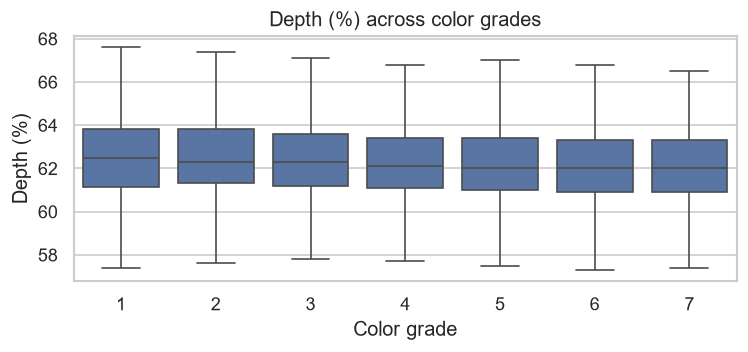

**Graph explanation.** Grade 5 has the lowest median (62.00). Grade 1 has the highest (62.50). The boxes and whiskers show the central range, with extreme markers hidden.

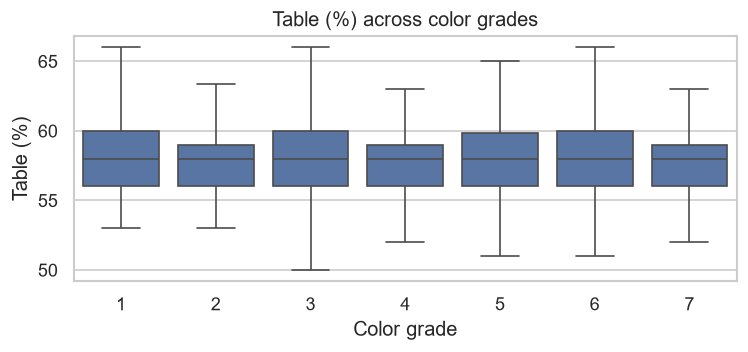

**Graph explanation.** Grade 1 has the lowest median (58.00). Grade 1 has the highest (58.00). The boxes and whiskers show the central range, with extreme markers hidden.

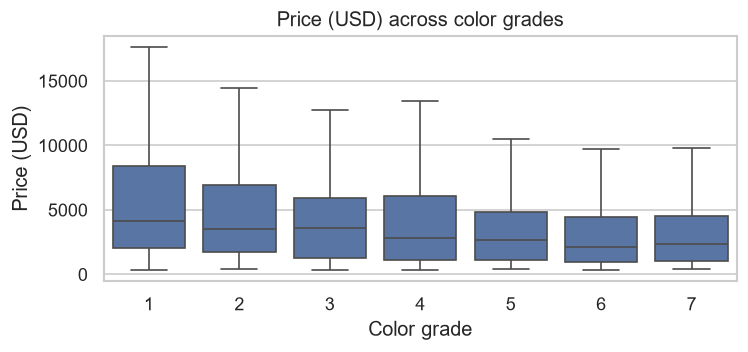

**Graph explanation.** Grade 6 has the lowest median (2,112.00). Grade 1 has the highest (4,104.00). The boxes and whiskers show the central range, with extreme markers hidden.

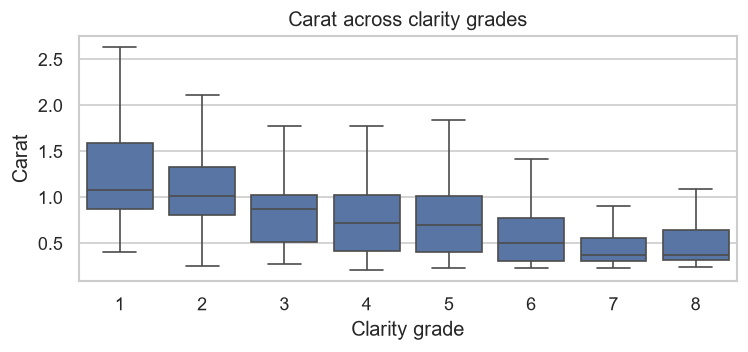

**Graph explanation.** Grade 7 has the lowest median (0.37). Grade 1 has the highest (1.08). The boxes and whiskers show the central range, with extreme markers hidden.

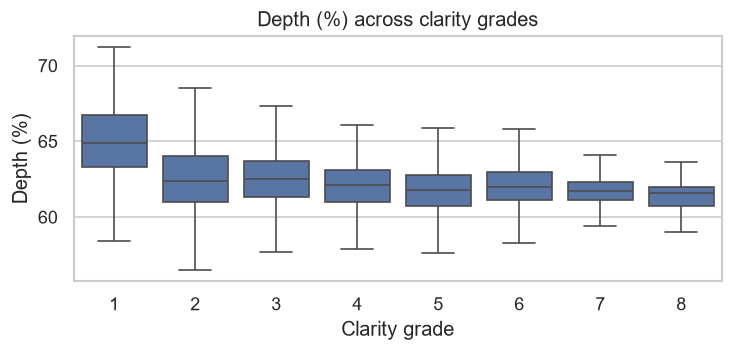

**Graph explanation.** Grade 8 has the lowest median (61.60). Grade 1 has the highest (64.90). The boxes and whiskers show the central range, with extreme markers hidden.

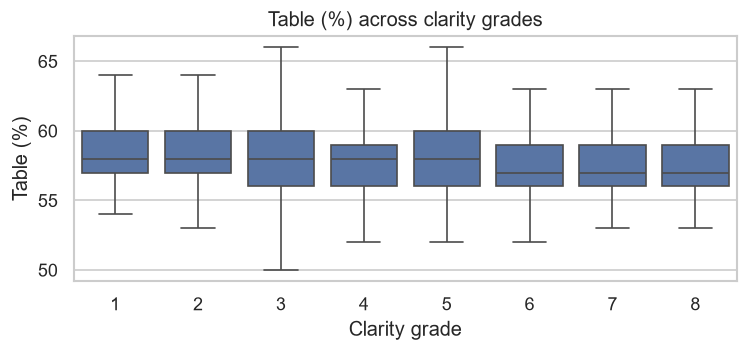

**Graph explanation.** Grade 6 has the lowest median (57.00). Grade 1 has the highest (58.00). The boxes and whiskers show the central range, with extreme markers hidden.

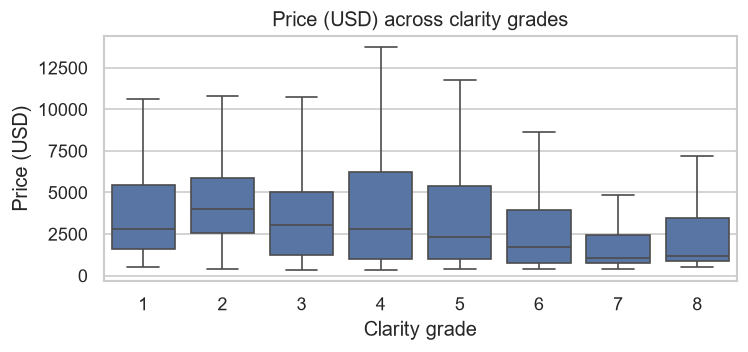

**Graph explanation.** Grade 7 has the lowest median (1,052.00). Grade 2 has the highest (3,991.00). The boxes and whiskers show the central range, with extreme markers hidden.

In [112]:
# Put the most populated category and median endpoints in context.
for grade in ["color_grade", "clarity_grade"]:
    for measure in ["carat", "depth_pct", "table_pct", "price_usd"]:
        group = df_init.groupby(grade)[measure]
        medians = group.median()
        low, high = medians.idxmin(), medians.idxmax()
        fig, ax = plt.subplots(figsize=(6.4, 3.1))
        sns.boxplot(data=df_init, x=grade, y=measure, showfliers=False, ax=ax)
        ax.set(xlabel=eda_names[grade], ylabel=eda_names[measure],
               title=f"{eda_names[measure]} across {eda_names[grade].lower()}s")
        eda_show(fig, f"Grade {low} has the lowest median ({medians[low]:,.2f}). "
                 f"Grade {high} has the highest ({medians[high]:,.2f}). "
                 "The boxes and whiskers show the central range, with extreme markers hidden.")

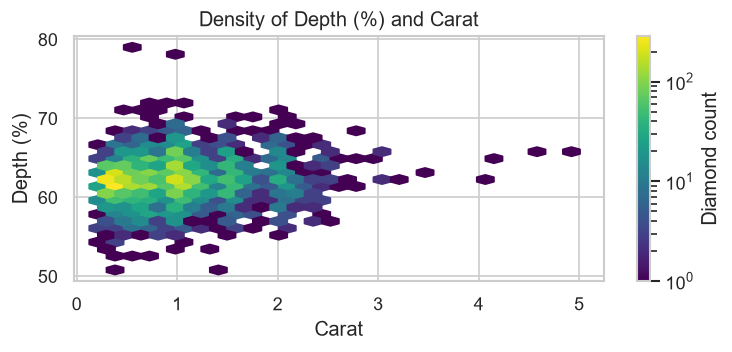

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,968 plotted diamonds is +0.10.

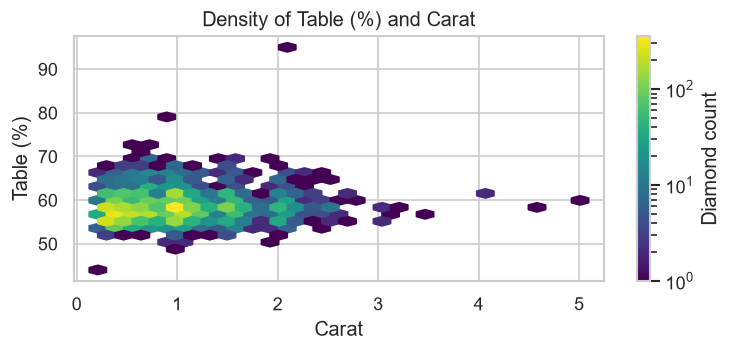

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,968 plotted diamonds is +0.16.

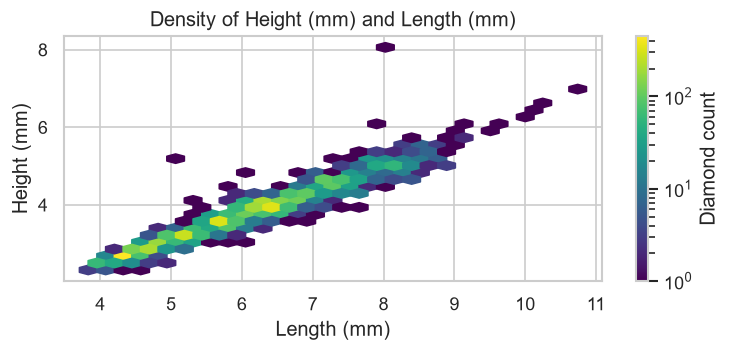

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,997 plotted diamonds is +0.97. The display omits dimensions above 30 mm.

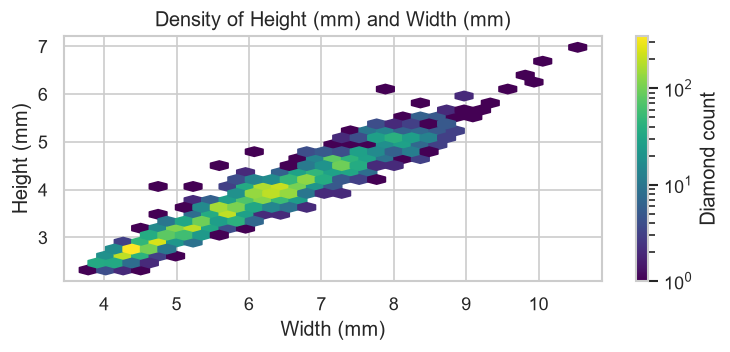

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,995 plotted diamonds is +0.97. The display omits dimensions above 30 mm.

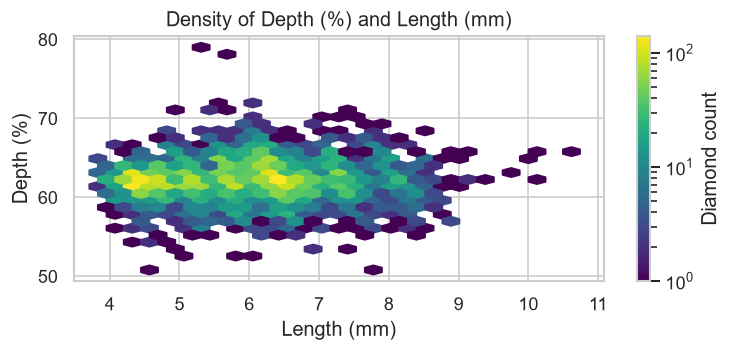

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,968 plotted diamonds is +0.02. The display omits dimensions above 30 mm.

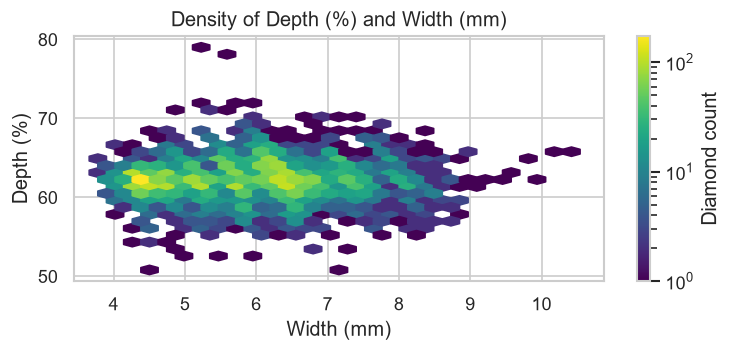

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,966 plotted diamonds is +0.01. The display omits dimensions above 30 mm.

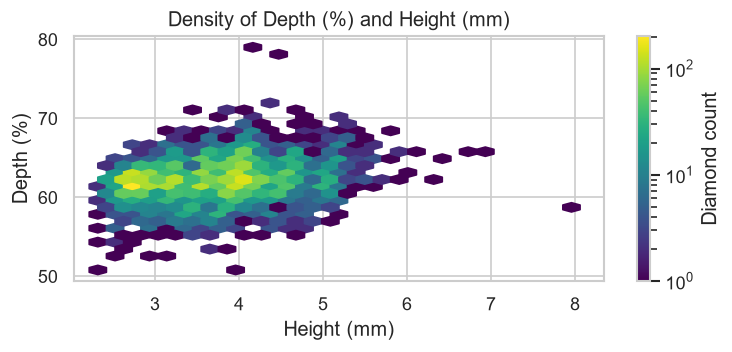

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,967 plotted diamonds is +0.21. The display omits dimensions above 30 mm.

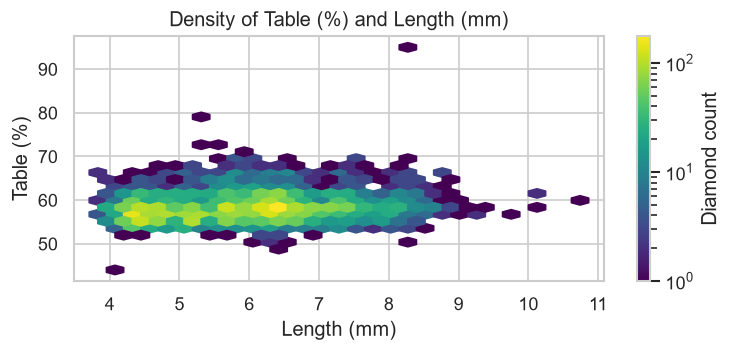

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,968 plotted diamonds is +0.18. The display omits dimensions above 30 mm.

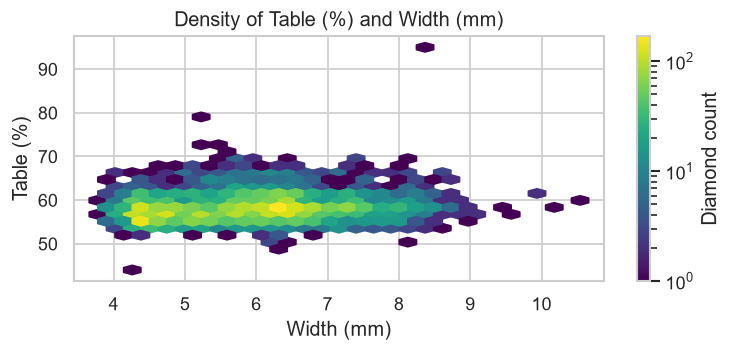

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,966 plotted diamonds is +0.18. The display omits dimensions above 30 mm.

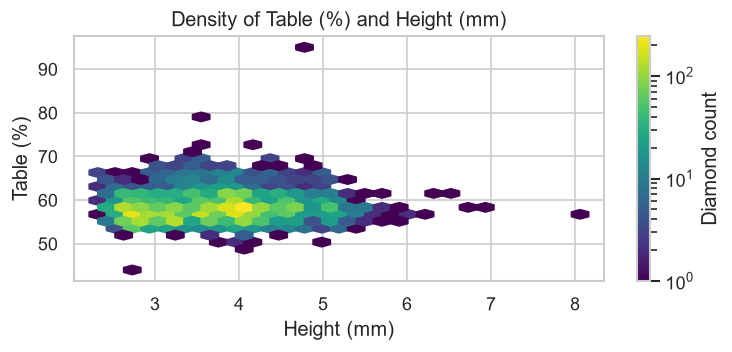

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,967 plotted diamonds is +0.11. The display omits dimensions above 30 mm.

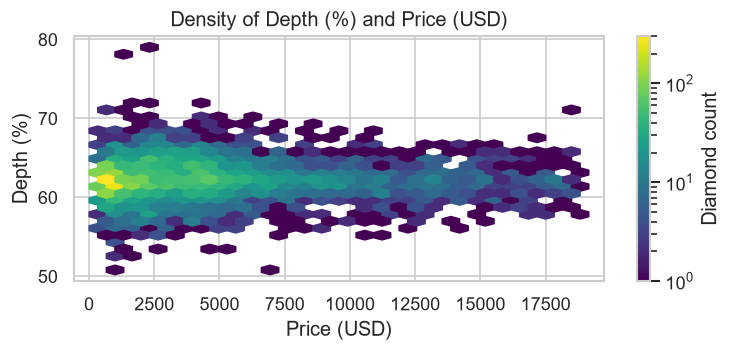

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,968 plotted diamonds is +0.03.

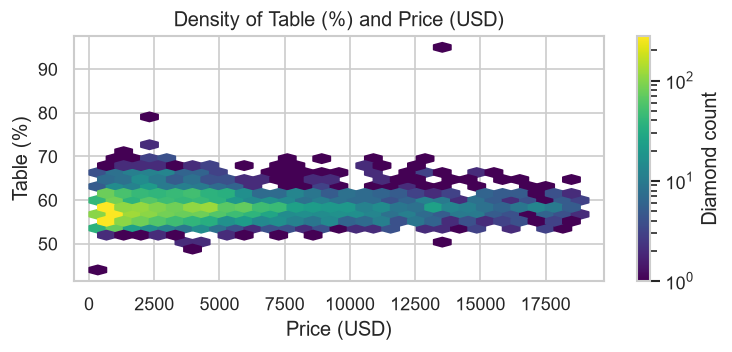

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,968 plotted diamonds is +0.15.

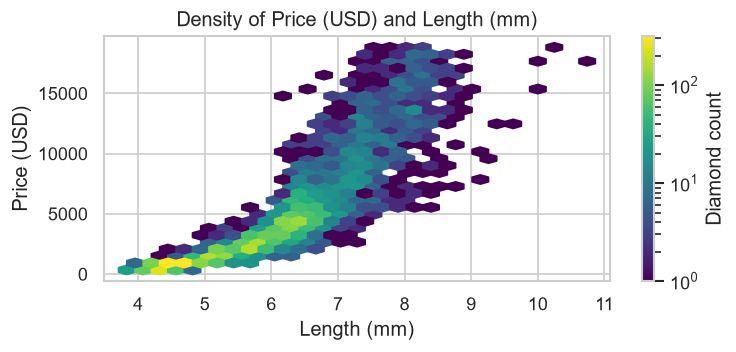

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,998 plotted diamonds is +0.96. The display omits dimensions above 30 mm.

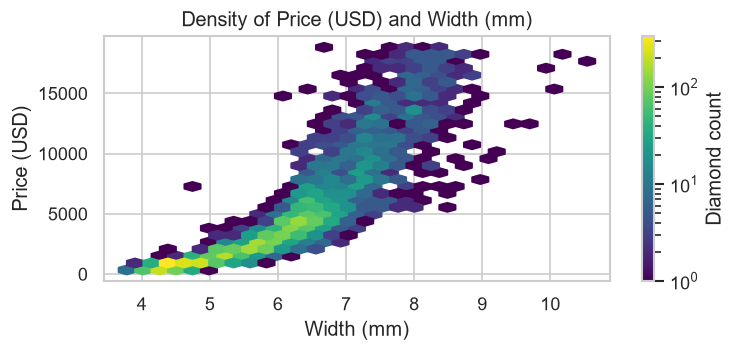

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,996 plotted diamonds is +0.96. The display omits dimensions above 30 mm.

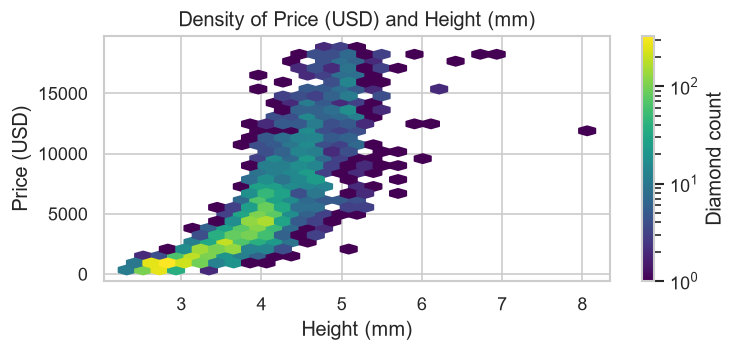

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,997 plotted diamonds is +0.94. The display omits dimensions above 30 mm.

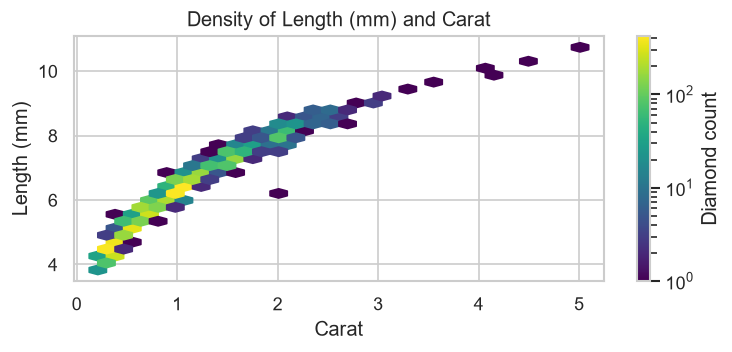

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,998 plotted diamonds is +0.99. The display omits dimensions above 30 mm.

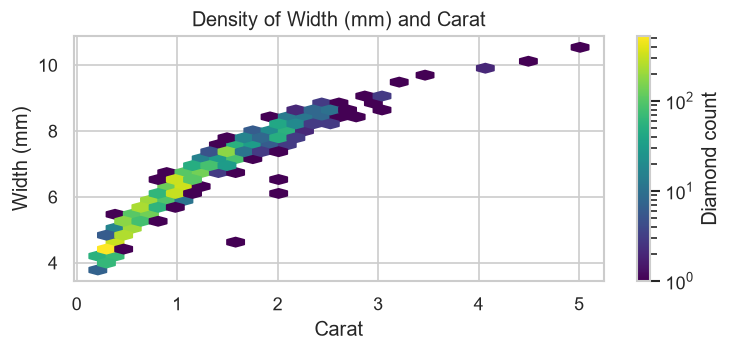

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,996 plotted diamonds is +0.99. The display omits dimensions above 30 mm.

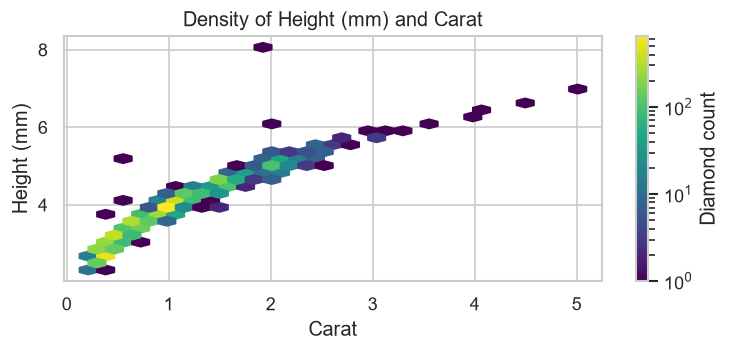

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,997 plotted diamonds is +0.99. The display omits dimensions above 30 mm.

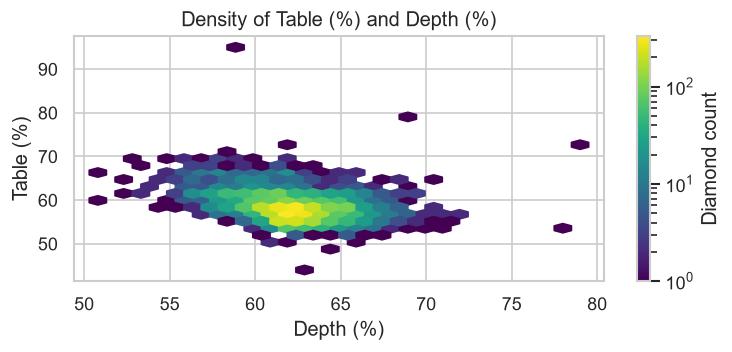

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,938 plotted diamonds is -0.30.

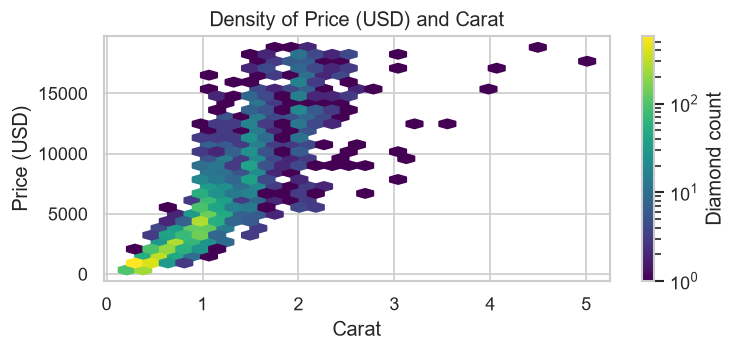

**Graph explanation.** The brighter cells contain more observations. Spearman correlation for the 4,998 plotted diamonds is +0.96.

In [113]:
# Hexagons make crowded feature combinations visible.
eda_pairs = [
    ("carat", "depth_pct"), ("carat", "table_pct"),
    ("length_mm", "height_mm"), ("width_mm", "height_mm"),
    ("length_mm", "depth_pct"), ("width_mm", "depth_pct"), ("height_mm", "depth_pct"),
    ("length_mm", "table_pct"), ("width_mm", "table_pct"), ("height_mm", "table_pct"),
    ("price_usd", "depth_pct"), ("price_usd", "table_pct"),
    ("length_mm", "price_usd"), ("width_mm", "price_usd"), ("height_mm", "price_usd"),
    ("carat", "length_mm"), ("carat", "width_mm"), ("carat", "height_mm"),
    ("depth_pct", "table_pct"), ("carat", "price_usd"),
]
for x, y in eda_pairs:
    subset = df_init[[x, y]].dropna()
    dimension_features = [f for f in [x, y] if f.endswith("_mm")]
    if dimension_features:
        subset = subset.loc[subset[dimension_features].lt(30).all(axis=1)]
    strength = subset[x].corr(subset[y], method="spearman")
    fig, ax = plt.subplots(figsize=(6.4, 3.1))
    hexes = ax.hexbin(subset[x], subset[y], gridsize=28, bins="log", mincnt=1, cmap="viridis")
    fig.colorbar(hexes, ax=ax, label="Diamond count")
    ax.set(xlabel=eda_names[x], ylabel=eda_names[y],
           title=f"Density of {eda_names[y]} and {eda_names[x]}")
    selection = " The display omits dimensions above 30 mm." if dimension_features else ""
    eda_show(fig, f"The brighter cells contain more observations. Spearman correlation "
             f"for the {len(subset):,} plotted diamonds is {strength:+.2f}.{selection}")

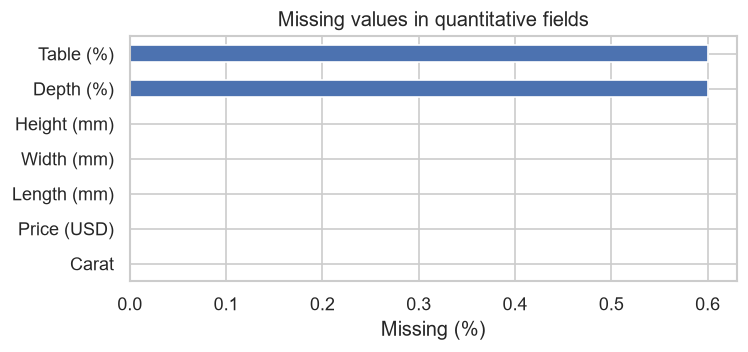

**Graph explanation.** Depth and table percentages each have about 0.60% missing values. The other displayed measurements are present.

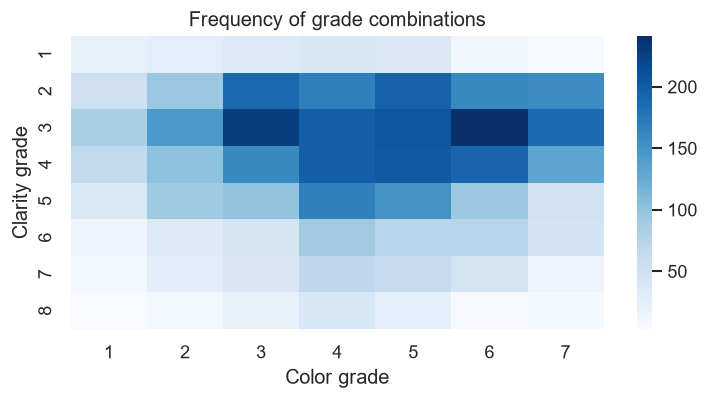

**Graph explanation.** The most frequent combination is clarity 3 and color 6 (241 diamonds).

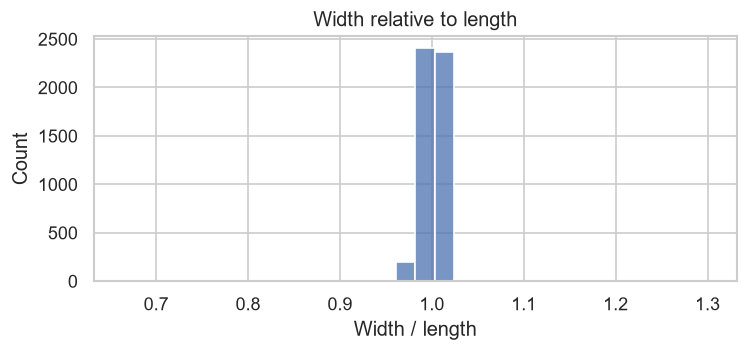

**Graph explanation.** The typical ratio is close to 1 (median 0.997), so most diamonds have similar width and length. Ratios above 1.30 are displayed at 1.30.

In [114]:
# Show missingness, grade combinations and within-stone shape.
missing_pct = df_init[eda_numeric].isna().mean().mul(100)
fig, ax = plt.subplots(figsize=(6.4, 3.1))
missing_pct.rename(index=eda_names).plot.barh(ax=ax)
ax.set(xlabel="Missing (%)", title="Missing values in quantitative fields")
eda_show(fig, "Depth and table percentages each have about 0.60% missing values. "
         "The other displayed measurements are present.")

grade_counts = pd.crosstab(df_init["clarity_grade"], df_init["color_grade"])
fig, ax = plt.subplots(figsize=(6.4, 3.5))
sns.heatmap(grade_counts, cmap="Blues", ax=ax)
ax.set(xlabel="Color grade", ylabel="Clarity grade", title="Frequency of grade combinations")
popular = grade_counts.stack().idxmax()
eda_show(fig, f"The most frequent combination is clarity {popular[0]} and color {popular[1]} "
         f"({grade_counts.loc[popular]:,} diamonds).")

dimension_ratio = df_init["width_mm"].div(df_init["length_mm"])
fig, ax = plt.subplots(figsize=(6.4, 3.1))
sns.histplot(x=dimension_ratio.clip(upper=1.3), bins=30, ax=ax)
ax.set(xlabel="Width / length", title="Width relative to length")
eda_show(fig, f"The typical ratio is close to 1 (median {dimension_ratio.median():.3f}), "
         "so most diamonds have similar width and length. Ratios above 1.30 are displayed at 1.30.")

### Modeling sample

The model uses complete cases because the eight features feed distance and dimensionality-reduction calculations, and the 60 rows with a missing proportion are about 1.2% of the records. A 3-IQR rule on carat-adjusted dimensions and on the two proportions also limits the influence of extreme measurements. For example, two widths over 30 mm and a height of 31.8 mm conflict with the recorded weights and other dimensions. The statistical rule can also exclude valid extremes, so the analysis describes the retained sample.

In [115]:
# Remove extreme outliers before dimensionality reduction

dimension_cols = ['length_mm', 'width_mm', 'height_mm']
proportion_cols = ['depth_pct', 'table_pct']

# Complete-case exclusion is explicit before applying the outlier rules.
mask = df_init[dimension_cols + proportion_cols + ['carat', 'color_grade', 'clarity_grade']].notna().all(axis=1)
print(f'Rows with missing modeling features: {(~mask).sum()}')

# Carat-adjusted IQR for physical dimensions
for col in dimension_cols:
    ratio = df_init[col] / np.cbrt(df_init['carat'])

    Q1 = ratio.quantile(0.25)
    Q3 = ratio.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 3 * IQR
    upper = Q3 + 3 * IQR

    mask &= ratio.between(lower, upper)

# Regular IQR for percentage features
for col in proportion_cols:
    Q1 = df_init[col].quantile(0.25)
    Q3 = df_init[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 3 * IQR
    upper = Q3 + 3 * IQR

    mask &= df_init[col].between(lower, upper)

# Create the cleaned dataset
df_clean = df_init[mask].copy()

print(f"Rows before complete-case and 3-IQR exclusions: {len(df_init)}")
print(f"Rows after both exclusions: {len(df_clean)}")
print(f"Total rows removed: {len(df_init) - len(df_clean)}")
print(f"Percentage retained: {len(df_clean) / len(df_init):.2%}")

Rows with missing modeling features: 60
Rows before complete-case and 3-IQR exclusions: 4998
Rows after both exclusions: 4889
Total rows removed: 109
Percentage retained: 97.82%


In [116]:
# Verify the retained model rows after the existing exclusions.
feature_names = [
    "carat", "depth_pct", "table_pct", "length_mm", "width_mm",
    "height_mm", "color_grade", "clarity_grade",
]
assert df_clean[feature_names].notna().all().all()
assert df_clean[dimension_cols].gt(0).all().all()
assert not df_clean.drop(columns="diamond_id").duplicated().any()

missing_feature_rows = df_init[feature_names].isna().any(axis=1)
extreme_complete_rows = (~missing_feature_rows & ~df_init.index.isin(df_clean.index)).sum()
print(f"Complete rows excluded by the 3-IQR rule: {extreme_complete_rows:,}")
print(f"Final modeling sample: {len(df_clean):,} of {raw_row_count:,} original rows")

Complete rows excluded by the 3-IQR rule: 49
Final modeling sample: 4,889 of 5,023 original rows


## 2. Dimensionality reduction

The original feature space has eight columns. Standardization gives each column unit variance before PCA, t-SNE, and original-space clustering. Treating ordered grades as numbers assumes equal spacing between adjoining grades. Carat and three correlated dimensions can jointly give size substantial influence. NMF uses Min-Max scaling to obtain nonnegative input.

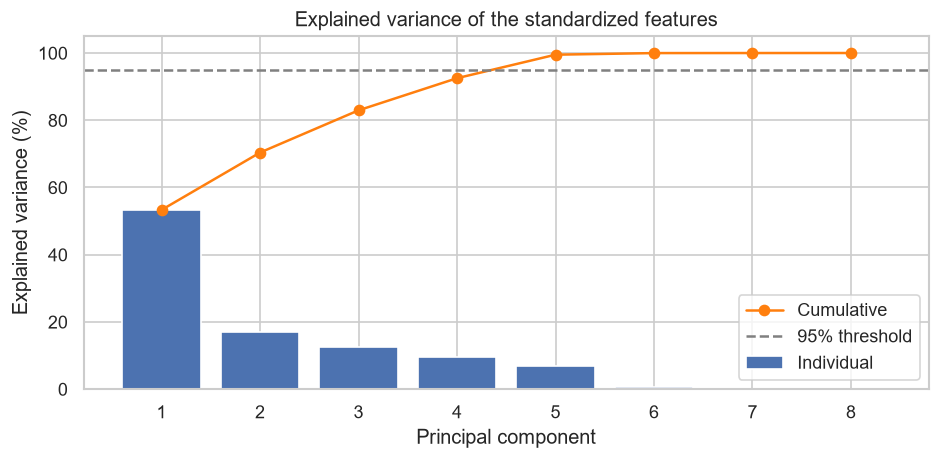

**Graph explanation.** The first two components explain 70.4% and the first three explain 82.9%. The threshold retains 5 components (99.5%).

In [117]:
seed = 42
X = df_clean[feature_names]
X_standard = StandardScaler().fit_transform(X)
X_nonnegative = MinMaxScaler().fit_transform(X)
pca = PCA().fit(X_standard)
pca_scores = pca.transform(X_standard)
variance = 100 * pca.explained_variance_ratio_
variance_total = np.cumsum(variance)
n_pca = np.searchsorted(variance_total, 95) + 1

fig, ax = plt.subplots(figsize=(8, 4))
pcs = np.arange(1, 1 + X.shape[1])
ax.bar(pcs, variance, label="Individual")
ax.plot(pcs, variance_total, "o-", color="tab:orange", label="Cumulative")
ax.axhline(95, color="grey", ls="--", label="95% threshold")
ax.set(xlabel="Principal component", ylabel="Explained variance (%)",
       title="Explained variance of the standardized features", xticks=pcs, ylim=(0, 105))
ax.legend()
fig.tight_layout()
plt.show()
display(Markdown(f"**Graph explanation.** The first two components explain "
                 f"{variance_total[1]:.1f}% and the first three explain {variance_total[2]:.1f}%. "
                 f"The threshold retains {n_pca} components ({variance_total[n_pca - 1]:.1f}%)."))

PCA shows a linear rotation of the standardized features. NMF describes observations through additive, nonnegative component weights. t-SNE emphasizes local neighborhoods. The positions and distances between far-apart t-SNE regions need particular care when interpreting clusters.

In [118]:
# Store each representation for the two clustering methods.
spaces = {
    "Original": X_standard,
    f"PCA {n_pca}D": pca_scores[:, :n_pca],
    "PCA 2D": pca_scores[:, :2],
    "PCA 3D": pca_scores[:, :3],
}
reduction_rows = []
for dimensions in (2, 3):
    nmf = NMF(n_components=dimensions, init="nndsvda", random_state=seed, max_iter=2000)
    tsne = TSNE(n_components=dimensions, perplexity=30, init="pca", random_state=seed)

    spaces[f"NMF {dimensions}D"] = nmf.fit_transform(X_nonnegative)
    spaces[f"t-SNE {dimensions}D"] = tsne.fit_transform(X_standard)
    reduction_rows.append({
        "Dimensions": dimensions,
        "PCA retained variance (%)": variance_total[dimensions - 1],
        "NMF relative reconstruction error (%)": (
            100 * nmf.reconstruction_err_ / np.linalg.norm(X_nonnegative)
        ),
        "t-SNE KL divergence": tsne.kl_divergence_,
    })
display(pd.DataFrame(reduction_rows).round(3))

,Dimensions,PCA retained variance (%),NMF relative reconstruction error (%),t-SNE KL divergence
0,2,70.372,27.594,1.477
1,3,82.942,18.121,1.250


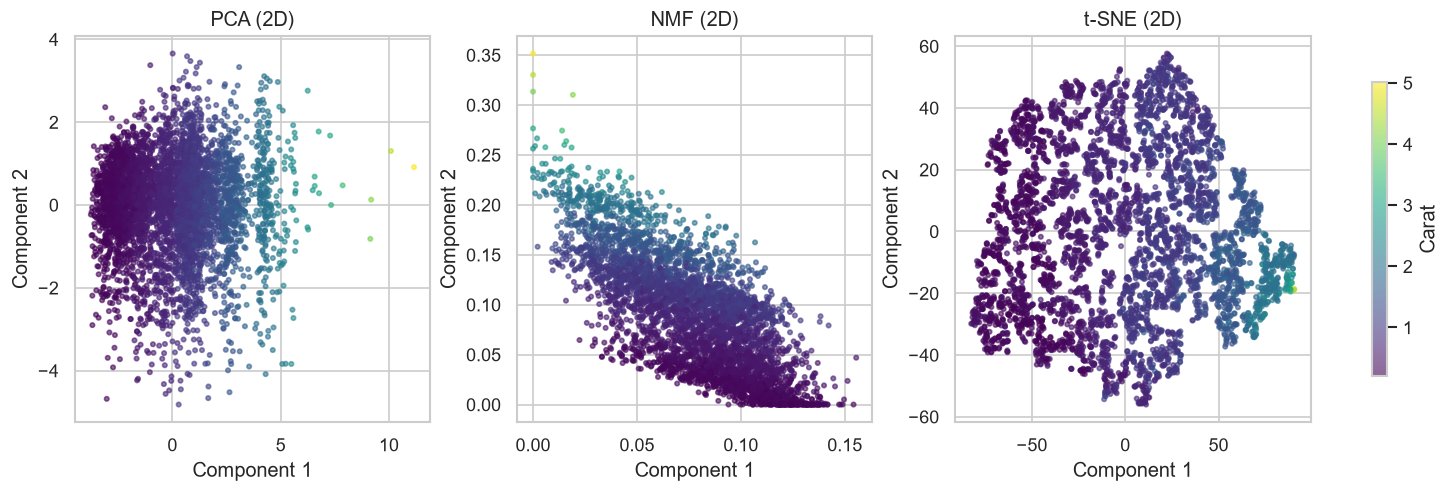

**Graph explanation.** In the 2D PCA panel, weight varies along a clear gradient. The NMF panel has nonnegative axes and a more constrained shape. t-SNE forms local neighborhoods with varying carat values. Color uses the same carat scale in all panels.

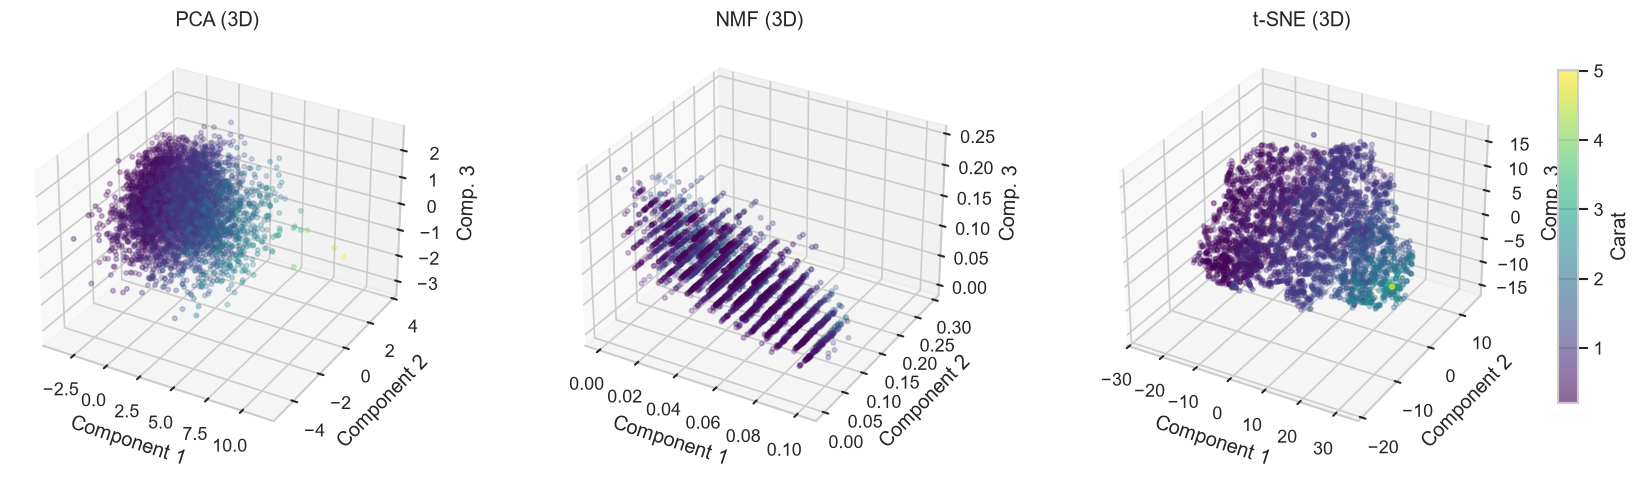

**Graph explanation.** In the 3D PCA panel, weight varies along a clear gradient. The NMF panel has nonnegative axes and a more constrained shape. t-SNE forms local neighborhoods with varying carat values. Color uses the same carat scale in all panels.

In [119]:
# Color the finished embeddings by carat to compare the visible structure.
for dimensions in (2, 3):
    subplot = {"projection": "3d"} if dimensions == 3 else {}
    if dimensions == 3:
        # Add room between panels for the third axis and its labels.
        fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), subplot_kw=subplot)
        fig.subplots_adjust(left=.01, right=.90, bottom=.07, top=.92, wspace=.32)
    else:
        fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
    for ax, method in zip(axes, ("PCA", "NMF", "t-SNE")):
        view = spaces[f"{method} {dimensions}D"]
        points = ax.scatter(*view.T, c=df_clean["carat"], cmap="viridis", s=7, alpha=.60)
        ax.set(xlabel="Component 1", ylabel="Component 2", title=f"{method} ({dimensions}D)")
        if dimensions == 3:
            ax.set_zlabel("Comp. 3")
    if dimensions == 3:
        fig.colorbar(points, cax=fig.add_axes([.93, .19, .012, .63]), label="Carat")
    else:
        fig.colorbar(points, ax=axes, label="Carat", shrink=.76)
    plt.show()
    display(Markdown(f"**Graph explanation.** In the {dimensions}D PCA panel, "
                     "weight varies along a clear gradient. The NMF panel has nonnegative "
                     "axes and a more constrained shape. t-SNE forms local neighborhoods "
                     "with varying carat values. Color uses the same carat scale in all panels."))

## 3. Clustering

K-Means is fit for k from 1 through 12 in each space. The chosen elbow is the point with the greatest distance below the line joining the two ends of the rescaled inertia curve. This identifies where gains begin to diminish. All fits use the physical and ordinal features through their respective representations.

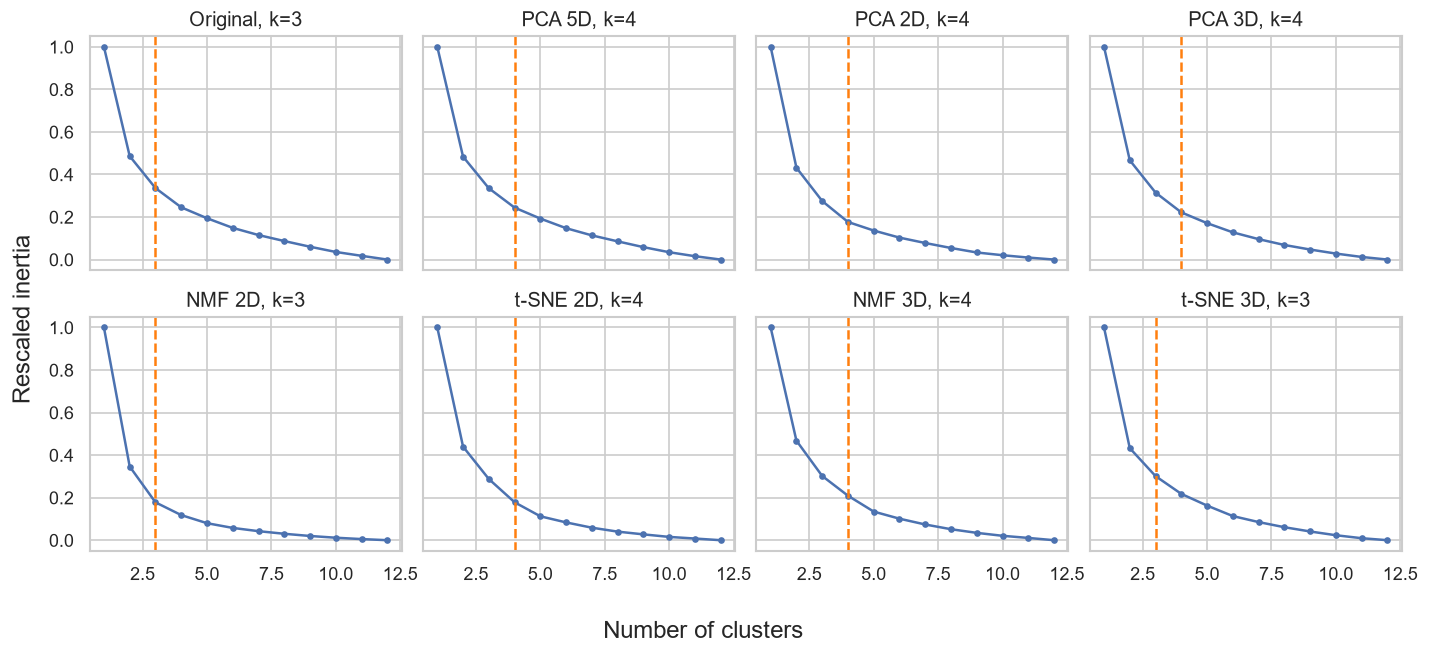

**Graph explanation.** The dashed line marks the selected elbow in each panel. Selected k values are Original 3, PCA 5D 4, PCA 2D 4, PCA 3D 4, NMF 2D 3, t-SNE 2D 4, NMF 3D 4, t-SNE 3D 3. Rescaling makes the shapes comparable across spaces.

In [121]:
# Fit the same range of k values in every feature space.
k_values = np.arange(1, 13)
kmeans_outputs = {}
kmeans_inertia = {}
kmeans_labels = {}
for name, points in spaces.items():
    fits = [KMeans(n_clusters=k, n_init=10, random_state=seed).fit(points) for k in k_values]
    scores = np.array([model.inertia_ for model in fits])
    normalized = (scores - scores[-1]) / (scores[0] - scores[-1])
    index = np.argmax(np.linspace(1, 0, len(scores)) - normalized)
    kmeans_outputs[name] = fits[index]
    kmeans_inertia[name] = normalized
    kmeans_labels[name] = fits[index].labels_

fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharex=True, sharey=True)
for (name, model), ax in zip(kmeans_outputs.items(), axes.ravel()):
    ax.plot(k_values, kmeans_inertia[name], "o-", ms=3)
    ax.axvline(model.n_clusters, color="tab:orange", ls="--")
    ax.set_title(f"{name}, k={model.n_clusters}")
fig.supxlabel("Number of clusters")
fig.supylabel("Rescaled inertia")
fig.tight_layout()
plt.show()
choices = ", ".join(f"{name} {m.n_clusters}" for name, m in kmeans_outputs.items())
display(Markdown(f"**Graph explanation.** The dashed line marks the selected elbow in "
                 f"each panel. Selected k values are {choices}. Rescaling makes "
                 "the shapes comparable across spaces."))

### DBSCAN parameter sweep

For each `min_samples` setting, candidate values of `eps` are quantiles of the corresponding nearest-neighbor distance. This lets different representations use their own distance scale. The selection uses the local silhouette multiplied by the fraction of assigned observations. A candidate needs at least two clusters. The table reports both quantities because a high silhouette on a small assigned subset gives limited coverage.

In [122]:
# Score a reproducible sample of the assigned diamonds.
def sample_silhouette(points, labels, keep):
    selected = np.flatnonzero(keep)
    if len(selected) > 1000:
        selected = np.random.default_rng(seed).choice(selected, 1000, replace=False)
    selection = labels[selected]
    if 2 <= len(np.unique(selection)) < len(selection):
        return silhouette_score(points[selected], selection)
    return np.nan

dbscan_rows = []
dbscan_labels = {}
for name, points in spaces.items():
    candidates = []
    for min_samples in (5, 10, 20):
        nearest = NearestNeighbors(n_neighbors=min_samples).fit(points)
        kth_distance = nearest.kneighbors(points, return_distance=True)[0][:, -1]
        for q in (.35, .50, .65, .80, .90, .96):
            eps = float(np.quantile(kth_distance, q))
            labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(points)
            keep = labels >= 0
            n_clusters = len(np.unique(labels[keep]))
            coverage = keep.mean()
            silhouette = sample_silhouette(points, labels, keep)
            row = {
                "Space": name, "min_samples": min_samples, "eps": eps,
                "Quantile": q, "Clusters": n_clusters, "Coverage": coverage,
                "Local silhouette": silhouette, "Selection score": silhouette * coverage,
            }
            candidates.append((row, labels))
    eligible = [(row, labels) for row, labels in candidates if np.isfinite(row["Selection score"])]
    picked, labels = max(eligible, key=lambda candidate: candidate[0]["Selection score"])
    dbscan_labels[name] = labels
    dbscan_rows.extend({**row, "Selected": row is picked} for row, _ in candidates)

dbscan_search = pd.DataFrame(dbscan_rows)
selected_dbscan = dbscan_search[dbscan_search["Selected"]].set_index("Space")
display(selected_dbscan[["min_samples", "eps", "Clusters", "Coverage", "Local silhouette"]].round(3))

,min_samples,eps,Clusters,Coverage,Local silhouette
Space,,,,,
Original,20,0.926,2,0.759,0.338
PCA 5D,20,0.922,2,0.759,0.344
PCA 2D,5,0.298,5,0.973,0.476
PCA 3D,10,0.501,3,0.895,0.385
NMF 2D,20,0.007,2,0.955,0.424
t-SNE 2D,5,1.363,372,0.744,0.482
NMF 3D,5,0.005,166,0.625,0.413
t-SNE 3D,5,1.089,363,0.726,0.453


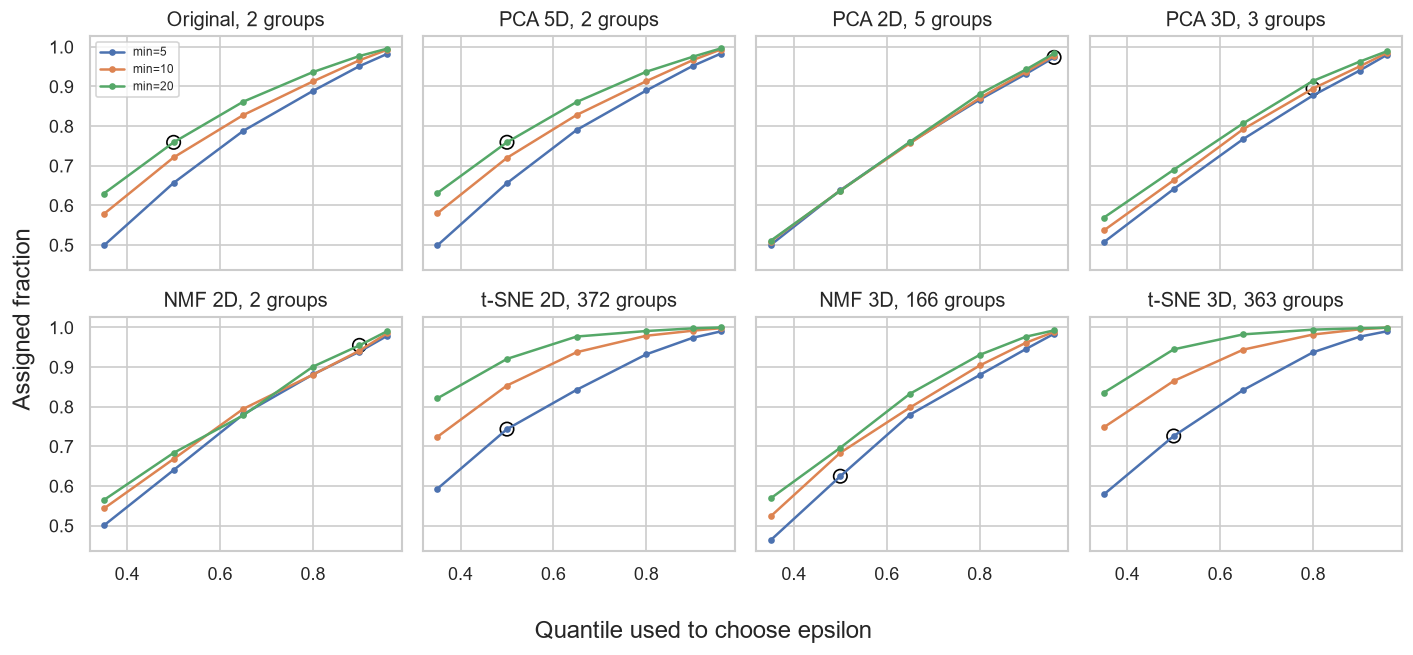

**Graph explanation.** Each line follows one minimum-neighbor setting. Larger epsilon values generally assign more diamonds. The open circles mark the settings chosen by the coverage-adjusted silhouette, so their locations and cluster counts differ across panels.

In [123]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharex=True, sharey=True)
for (name, group), ax in zip(dbscan_search.groupby("Space", sort=False), axes.ravel()):
    for m, path in group.groupby("min_samples"):
        ax.plot(path["Quantile"], path["Coverage"], "o-", ms=3, label=f"min={m}")
    row = group[group["Selected"]].iloc[0]
    ax.scatter(row["Quantile"], row["Coverage"], s=65, facecolors="none", edgecolors="black")
    ax.set_title(f"{name}, {int(row['Clusters'])} groups")
axes[0, 0].legend(fontsize=7)
fig.supxlabel("Quantile used to choose epsilon")
fig.supylabel("Assigned fraction")
fig.tight_layout()
plt.show()
display(Markdown("**Graph explanation.** Each line follows one minimum-neighbor setting. "
                 "Larger epsilon values generally assign more diamonds. The open circles mark "
                 "the settings chosen by the coverage-adjusted silhouette, so their locations "
                 "and cluster counts differ across panels."))

## 4. Comparison and interpretation

Each partition is evaluated in the standardized original space. Silhouette measures separation on assigned points. DBSCAN can leave observations as noise, so silhouette is reported alongside coverage. Adjusted Rand index (ARI) compares assignment agreement with the original-space K-Means partition on the assigned subset. Labels are arbitrary, and both measures describe the fitted partitions of this sample.

In [124]:
# Compare all labelings in the original feature space.
all_partitions = {"K-Means": kmeans_labels, "DBSCAN": dbscan_labels}
comparison_rows = []
for algorithm, partitions in all_partitions.items():
    for name, labels in partitions.items():
        keep = labels >= 0
        comparison_rows.append({
            "Algorithm": algorithm, "Space": name,
            "Clusters": len(np.unique(labels[keep])),
            "Coverage": keep.mean(),
            "Original silhouette": sample_silhouette(X_standard, labels, keep),
            "ARI vs original K-Means": adjusted_rand_score(
                kmeans_labels["Original"][keep], labels[keep]
            ),
        })
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))

,Algorithm,Space,Clusters,Coverage,Original silhouette,ARI vs original K-Means
0,K-Means,Original,3,1.000,0.251,1.000
1,K-Means,PCA 5D,4,1.000,0.242,0.728
2,K-Means,PCA 2D,4,1.000,0.240,0.701
3,K-Means,PCA 3D,4,1.000,0.240,0.711
4,K-Means,NMF 2D,3,1.000,0.210,0.635
5,K-Means,t-SNE 2D,4,1.000,0.183,0.505
6,K-Means,NMF 3D,4,1.000,0.114,0.227
7,K-Means,t-SNE 3D,3,1.000,0.243,0.875
8,DBSCAN,Original,2,0.759,0.338,0.043
9,DBSCAN,PCA 5D,2,0.759,0.346,0.041


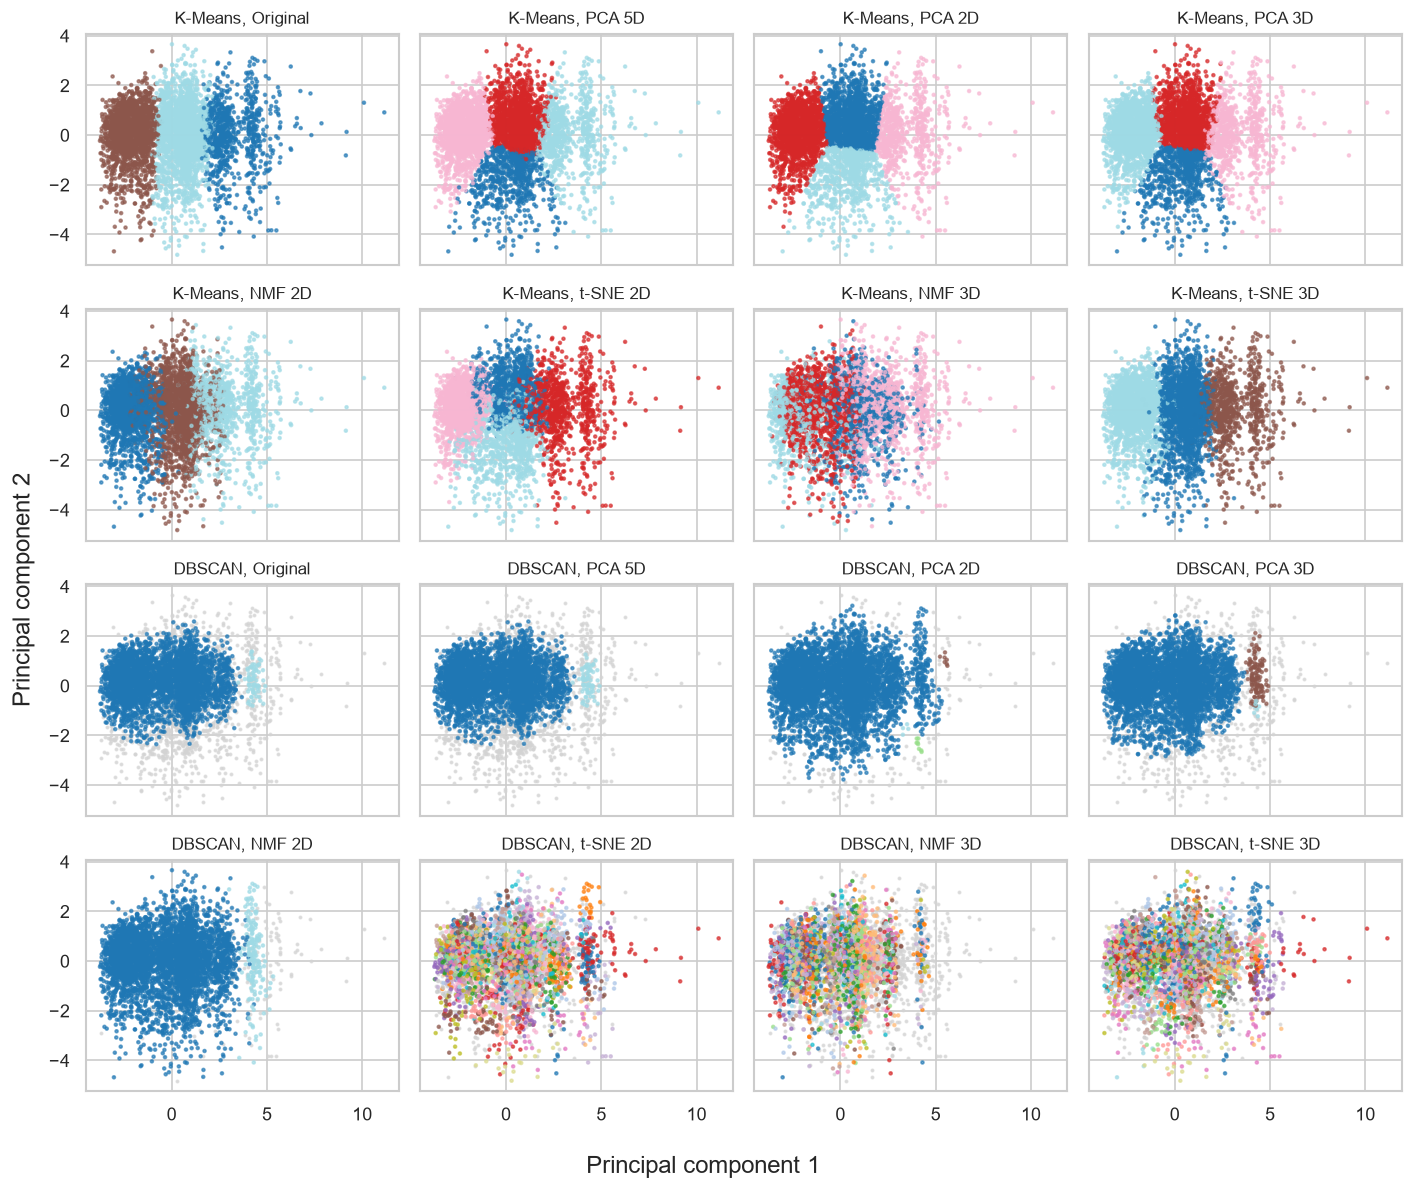

**Graph explanation.** Each panel places the same diamonds on the first two principal components and colors them by its fitted labels. Gray marks DBSCAN noise. Groups can overlap on this two-axis display even when they are separated in the space used for the fit.

In [125]:
# Project every partition onto the same PCA plane for comparison.
fig, axes = plt.subplots(4, 4, figsize=(12, 10), sharex=True, sharey=True)
for row_group, (algorithm, partitions) in enumerate(all_partitions.items()):
    for index, (name, labels) in enumerate(partitions.items()):
        ax = axes[2 * row_group + index // 4, index % 4]
        noise = labels == -1
        ax.scatter(*pca_scores[noise, :2].T, c="lightgrey", s=2, alpha=.65)
        ax.scatter(*pca_scores[~noise, :2].T, c=labels[~noise], cmap="tab20", s=3, alpha=.65)
        ax.set_title(f"{algorithm}, {name}", fontsize=10)
fig.supxlabel("Principal component 1")
fig.supylabel("Principal component 2")
fig.tight_layout()
plt.show()
display(Markdown("**Graph explanation.** Each panel places the same diamonds on the first "
                 "two principal components and colors them by its fitted labels. Gray marks "
                 "DBSCAN noise. Groups can overlap on this two-axis display even when they "
                 "are separated in the space used for the fit."))

In [126]:
# Add price after every fit and parameter choice is complete.
def cluster_profile(labels):
    labeled = df_clean.assign(cluster=labels)
    return labeled.groupby("cluster").agg(
        Diamonds=("carat", "size"), Carat=("carat", "median"),
        Length=("length_mm", "median"), Width=("width_mm", "median"),
        Height=("height_mm", "median"), Depth=("depth_pct", "median"),
        Table=("table_pct", "median"), Color=("color_grade", "median"),
        Clarity=("clarity_grade", "median"), Price_USD=("price_usd", "median"),
    ).sort_values("Carat")

original_profile = cluster_profile(kmeans_labels["Original"])
print("Original-space K-Means (cluster medians)")
display(original_profile.round(2))

db_compare = comparison[comparison["Algorithm"] == "DBSCAN"].copy()
db_compare["Coverage-adjusted original silhouette"] = db_compare["Coverage"] * db_compare["Original silhouette"]
db_choice = db_compare.loc[db_compare["Coverage-adjusted original silhouette"].idxmax()]
db_space = db_choice["Space"]
db_profile = cluster_profile(dbscan_labels[db_space])
print(f"DBSCAN on {db_space} (cluster medians, -1 denotes noise)")
display(db_profile.head(12).round(2))

Original-space K-Means (cluster medians)


,Diamonds,Carat,Length,Width,Height,Depth,Table,Color,Clarity,Price_USD
cluster,,,,,,,,,,
1,1827,0.40,4.68,4.70,2.89,61.9,57.0,5.0,4.0,886.0
2,2242,1.00,6.25,6.22,3.90,62.3,58.0,4.0,3.0,3871.0
0,820,1.54,7.45,7.46,4.64,62.4,58.0,3.0,3.0,10341.0


DBSCAN on PCA 2D (cluster medians, -1 denotes noise)


,Diamonds,Carat,Length,Width,Height,Depth,Table,Color,Clarity,Price_USD
cluster,,,,,,,,,,
3,4,0.70,5.86,5.87,3.36,57.50,66.0,4.5,4.5,2397.0
0,4736,0.77,5.87,5.87,3.66,62.10,58.0,4.0,4.0,2832.5
-1,130,1.51,7.45,7.44,4.56,59.30,62.0,3.0,2.0,7274.0
4,4,1.72,7.80,7.85,4.62,58.70,60.5,3.0,3.0,11198.0
1,8,2.01,8.21,8.22,4.80,58.25,62.0,3.0,3.0,15755.0
2,7,2.51,8.49,8.43,5.49,64.90,58.0,3.0,2.0,16842.0


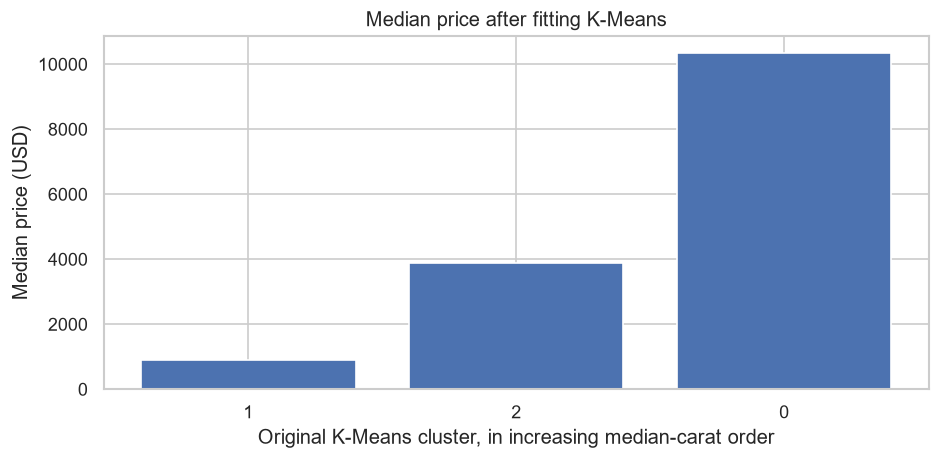

**Graph explanation.** In increasing order of median carat, cluster median prices are USD 886, USD 3,871, USD 10,341. The price differences describe the fitted groups and also reflect differences in size and grades.

In [127]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([str(cluster) for cluster in original_profile.index], original_profile["Price_USD"])
ax.set(xlabel="Original K-Means cluster, in increasing median-carat order",
       ylabel="Median price (USD)", title="Median price after fitting K-Means")
fig.tight_layout()
plt.show()
prices = original_profile["Price_USD"].map(lambda price: f"USD {price:,.0f}")
display(Markdown("**Graph explanation.** In increasing order of median carat, cluster "
                 f"median prices are {', '.join(prices)}. The price differences describe "
                 "the fitted groups and also reflect differences in size and grades."))

### Comparative summary

The analysis retained 4,889 diamonds. The original-feature K-Means elbow selected three groups with median weights of 0.40, 1.00 and 1.54 carats. Carat and the three dimensions carry much of the same size information. Their strong association helps explain why size is prominent in this partition.

Across reduced spaces, t-SNE 3D K-Means had the highest agreement with the original K-Means partition (adjusted Rand index 0.877). Both selected three groups. PCA retained 99.5% of the standardized variance in five components, and its four-group K-Means partition had an ARI of 0.728. Results on the two NMF representations differed substantially, with ARIs of 0.635 in 2D and 0.227 in 3D. The embedding and the elbow choice both influence the assignments.

DBSCAN on PCA 2D had the highest coverage-adjusted silhouette in the original feature space among the selected DBSCAN fits. It assigned 97.3% of the sample, but 4,736 diamonds belonged to one group and just 23 were spread among four small groups. Its noise points had a median weight of 1.51 carats, compared with 0.77 in the largest group. On t-SNE, the chosen DBSCAN settings gave 367 groups in 2D and 363 in 3D. These fits reveal density differences and fragmentation across representations.

After fitting, the three original K-Means groups had median prices of USD 886, USD 3,871 and USD 10,341 in increasing order of median carat. The lightest group had a median color grade of 5 and clarity grade of 4, compared with 3 for both grades in the heaviest group. The profiles show how weight, dimensions and grades combine within groups and how prices vary across those combinations.